# Comprensión de datos y EDA

**Proyecto final de Machine Learning: predicción de pago a tiempo de créditos**

**Objetivo del negocio:** predecir si un cliente pagará su crédito a tiempo (`Pago_atiempo` = 1) o no (`Pago_atiempo` = 0), usando la información disponible al momento de la solicitud. Esto permite a la empresa aprobar créditos con menor riesgo y enfocar la gestión de cobranza.

**Tipo de problema:** clasificación binaria supervisada.

### Contenido
**Parte 1: exploracion inicial de datos**
1. Carga de datos
2. Descripción general
3. Caracterización de las variables
4. Revisión y unificacion de nulos
5. Conversion de tipos de datos
6. Eliminacion de variables irrelevantes

**Parte 2: exploracion de datos y descripcion (EDA)**

7. Analisis univariable
8. Analisis bivariable (frente a la variable objetivo)
9. Analisis multivariable
10. Reglas de validacion de datos
11. Transformaciones propuestas
12. Atributos derivados
13. Conclusiones

# Parte 1: exploracion inicial de datos

## 1. Carga de datos

en esta parte hacemos lo que seria la insercion de librerias para el notebook de  comprension y analisis del dataset: 

la librerias que veriamos para este trabajo seria los siguientes:
-matplotlib para los graficos.
-numpy para calculos numericos.
-pandas para manejo de tablas de datos.
-seaborn graficos estadisticos.
-scipy para las pruebas estadisticas.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")
COLORES_OBJETIVO = {0: "firebrick", 1: "steelblue"}


def con_sin_dato(serie: pd.Series) -> pd.Series:
    """Convierte una variable a texto y reemplaza los nulos por la etiqueta 'Sin dato'."""
    return serie.astype(object).where(serie.notna(), "Sin dato").astype(str)

aca se hace se busca el arhivo de la base_de_datos.csv y lo carga en la tabla df, ya lo que hace la funcion ruta_datos es que se encarga de mirar la carpeta actual y luego en la carpeta superior. esto lo hace porque el notebook esta dentro de mlops_pipeline y el csv esta en la raiz. esto para mas agilidad sin tener que escribir rutas a mano.

In [2]:
def obtener_ruta_datos(nombre_archivo: str = "Base_de_datos.csv") -> Path:
    """Busca el archivo de datos en la carpeta actual y en la carpeta superior."""
    for carpeta in [Path.cwd(), Path.cwd().parent]:
        ruta = carpeta / nombre_archivo
        if ruta.exists():
            return ruta
    raise FileNotFoundError(f"No se encontró '{nombre_archivo}' en la raíz del repositorio.")


df = pd.read_csv(obtener_ruta_datos(), parse_dates=["fecha_prestamo"])
df_original = df.copy()  # copia sin modificar, para validar reglas más adelante
print(f"Dimensiones: {df.shape[0]:,} filas y {df.shape[1]} columnas")
print(f"Filas duplicadas: {df.duplicated().sum()}")

Dimensiones: 10,763 filas y 23 columnas
Filas duplicadas: 0


## 2. Descripción general de los datos

en esta parte ponemos el metodo .head para ir mirando el dataset y muestre las priemras cinco filas de la tabla para ir viendo su estructura.

In [3]:
df.head()

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,2025-01-07 14:40:36,"1,852,560.00",12,32,Empleado,3500000,1000000,128650,95.23,795.00,0,2,0.00,0.00,NaN,NaN,0,0,0,"916,148.00",Creciente,1
1,4,2025-01-09 11:18:48,"3,181,080.00",6,34,Empleado,5000000,2000000,441817,95.23,796.00,0,7,0.00,0.00,NaN,NaN,0,0,0,"4,473,774.00",Creciente,1
2,9,2024-12-26 18:52:57,"670,200.00",5,34,Independiente,5000000,2000000,108632,95.23,727.00,5,0,0.00,"274,561.00","274,561.00",NaN,2,0,1,NaN,NaN,1
3,9,2024-12-04 14:20:50,"506,806.80",2,25,Independiente,3000000,900000,199684,95.23,864.00,8,1,0.00,"27,564.00","27,564.00",NaN,1,0,6,NaN,NaN,1
4,4,2025-04-30 18:41:57,"999,780.00",10,26,Empleado,2000000,600000,92509,95.23,771.00,0,3,0.00,0.00,NaN,NaN,0,0,0,"61,000.00",Creciente,1


aca lo que hacemos es que con el .info() nos mostrara un resumen tecnico de cada columna y cuantos valores nulos tiene cada dato en python. 

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10763 non-null  int64         
 1   fecha_prestamo                 10763 non-null  datetime64[us]
 2   capital_prestado               10763 non-null  float64       
 3   plazo_meses                    10763 non-null  int64         
 4   edad_cliente                   10763 non-null  int64         
 5   tipo_laboral                   10763 non-null  str           
 6   salario_cliente                10763 non-null  int64         
 7   total_otros_prestamos          10763 non-null  int64         
 8   cuota_pactada                  10763 non-null  int64         
 9   puntaje                        10763 non-null  float64       
 10  puntaje_datacredito            10757 non-null  float64       
 11  cant_creditosvigentes     

**Comentario:** la base tiene 10.763 detos de creditos y hya 23 variables, sin filas duplicadas. Cada fila es un credito otorgado entre noviembre de 2024 y abril de 2026. Las variables se agrupan en cuatro bloques:

- **Del credito:** `tipo_credito`, `fecha_prestamo`, `capital_prestado`, `plazo_meses`, `cuota_pactada`.
- **Del cliente:** `edad_cliente`, `tipo_laboral`, `salario_cliente`, `total_otros_prestamos`.
- **Del informes del credito (Datacrédito):** `puntaje_datacredito`, `cant_creditosvigentes`, `huella_consulta`, saldos, créditos por sector, `promedio_ingresos_datacredito`, `tendencia_ingresos`.
- **Otras y objetivo:** `puntaje` (puntaje interno) y `Pago_atiempo` (variable objetivo).

## 3. Caracterización de las variables

Clasificación usada:
- **Numerica continua:** puede tomar cualquier valor en un rango (dinero, puntajes).
- **Numerica discreta:** valores enteros contables (meses, edad, número de créditos).
- **Categorica nominal:** categorías sin orden.
- **Categrica ordinal:** categorías con un orden natural.
- **Dicotomica:** solo 2 categorías. 
- **Politomica:** más de 2 categorías.
- **Fecha:** variable temporal.


En esta parte del codigo construimos una tabla de caracterizacion . Primero, un diccionario define a mano, con criterio de negocio, el tipo estadístico de cada variable (numerica continua o discreta, categorica nominal u ordinal, o fecha) . porque python no siempre lo dice, luego  la funcion contruir_tabla_caracterizacion recorrera las columans y para cada una de las variables calculara cuanto valores distintos tiene cada, si es dicotomica o politomica, cuantos nulos tien. esto con para que cree una tabla con una fila por variable 

In [ ]:
caracterizacion = {
    # variable: (tipo_dato, subtipo, descripcion)
    "tipo_credito": ("Categórica", "Nominal", "Código del tipo de crédito"),
    "fecha_prestamo": ("Fecha", "Temporal", "Fecha y hora del desembolso"),
    "capital_prestado": ("Numérica", "Continua", "Monto prestado"),
    "plazo_meses": ("Numérica", "Discreta", "Plazo del crédito en meses"),
    "edad_cliente": ("Numérica", "Discreta", "Edad del cliente en años"),
    "tipo_laboral": ("Categórica", "Nominal", "Empleado o independiente"),
    "salario_cliente": ("Numérica", "Continua", "Salario declarado"),
    "total_otros_prestamos": ("Numérica", "Continua", "Monto de otros préstamos"),
    "cuota_pactada": ("Numérica", "Continua", "Valor de la cuota"),
    "puntaje": ("Numérica", "Continua", "Puntaje interno"),
    "puntaje_datacredito": ("Numérica", "Discreta", "Score de Datacrédito"),
    "cant_creditosvigentes": ("Numérica", "Discreta", "Número de créditos vigentes"),
    "huella_consulta": ("Numérica", "Discreta", "Consultas recientes al buró"),
    "saldo_mora": ("Numérica", "Continua", "Saldo en mora"),
    "saldo_total": ("Numérica", "Continua", "Saldo total de deudas"),
    "saldo_principal": ("Numérica", "Continua", "Saldo a capital"),
    "saldo_mora_codeudor": ("Numérica", "Continua", "Saldo en mora como codeudor"),
    "creditos_sectorFinanciero": ("Numérica", "Discreta", "Créditos en sector financiero"),
    "creditos_sectorCooperativo": ("Numérica", "Discreta", "Créditos en sector cooperativo"),
    "creditos_sectorReal": ("Numérica", "Discreta", "Créditos en sector real"),
    "promedio_ingresos_datacredito": ("Numérica", "Continua", "Ingreso promedio reportado al buró"),
    "tendencia_ingresos": ("Categórica", "Ordinal", "Decreciente < Estable < Creciente"),
    "Pago_atiempo": ("Categórica", "Nominal", "OBJETIVO: 1 = pagó a tiempo, 0 = no"),
}


def construir_tabla_caracterizacion(data: pd.DataFrame, dicc: dict) -> pd.DataFrame:
    """Arma una tabla con el tipo, la cardinalidad y los nulos de cada variable."""
    filas = []
    for col in data.columns:
        tipo_dato, subtipo, descripcion = dicc.get(col, ("Derivada", "-", "-"))
        n_unicos = data[col].nunique(dropna=True)
        if tipo_dato == "Categórica":
            cardinalidad = "Dicotómica" if n_unicos == 2 else "Politómica"
        else:
            cardinalidad = "No aplica"
        ejemplos = ", ".join(str(v) for v in data[col].dropna().unique()[:3])
        filas.append({
            "variable": col,
            "descripcion": descripcion,
            "tipo_python": str(data[col].dtype),
            "tipo_dato": tipo_dato,
            "subtipo": subtipo,
            "dicotomica/politomica": cardinalidad,
            "valores_unicos": n_unicos,
            "nulos": data[col].isna().sum(),
            "%_nulos": round(data[col].isna().mean() * 100, 2),
            "ejemplos": ejemplos,
        })
    return pd.DataFrame(filas)


tabla_caract = construir_tabla_caracterizacion(df, caracterizacion)
tabla_caract

,variable,descripcion,tipo_python,tipo_dato,subtipo,dicotomica/politomica,valores_unicos,nulos,%_nulos,ejemplos
0,tipo_credito,Código del tipo de crédito,int64,Categórica,Nominal,Politómica,6,0,0.00,"4, 9, 10"
1,fecha_prestamo,Fecha y hora del desembolso,datetime64[us],Fecha,Temporal,No aplica,10758,0,0.00,"2025-01-07 14:40:36, 2025-01-09 11:18:48, 2024..."
2,capital_prestado,Monto prestado,float64,Numérica,Continua,No aplica,7306,0,0.00,"1852560.0, 3181080.0, 670200.0"
3,plazo_meses,Plazo del crédito en meses,int64,Numérica,Discreta,No aplica,18,0,0.00,"12, 6, 5"
4,edad_cliente,Edad del cliente en años,int64,Numérica,Discreta,No aplica,54,0,0.00,"32, 34, 25"
5,tipo_laboral,Empleado o independiente,str,Categórica,Nominal,Dicotómica,2,0,0.00,"Empleado, Independiente"
6,salario_cliente,Salario declarado,int64,Numérica,Continua,No aplica,1385,0,0.00,"3500000, 5000000, 3000000"
7,total_otros_prestamos,Monto de otros préstamos,int64,Numérica,Continua,No aplica,1538,0,0.00,"1000000, 2000000, 900000"
8,cuota_pactada,Valor de la cuota,int64,Numérica,Continua,No aplica,9836,0,0.00,"128650, 441817, 108632"
9,puntaje,Puntaje interno,float64,Numérica,Continua,No aplica,248,0,0.00,"95.227787, 86.830187, 18.451409"


en esta parte se cuenta cuantas variables hay de cada tipo. por ejemplo cuantos hay dicotomicas , continua ... etc . sirve para mostrar un resumen de lo anterior.

In [ ]:
# Resumen de la caracterización
pd.crosstab(tabla_caract["tipo_dato"] + " " + tabla_caract["subtipo"],
            tabla_caract["dicotomica/politomica"], margins=True, margins_name="Total")

dicotomica/politomica,Dicotómica,No aplica,Politómica,Total
row_0,,,,
Categórica Nominal,2,0,1,3
Categórica Ordinal,0,0,1,1
Fecha Temporal,0,1,0,1
Numérica Continua,0,10,0,10
Numérica Discreta,0,8,0,8
Total,2,19,2,23


**Interpretacion:**
- **Categoricas (4):**
  - tipo_laboral : nominal dicotómica (Empleado / Independiente).
  - Pago_atiempo : nominal dicotómica, es la variable objetivo.
  - tipo_credito : nominal politómica (6 códigos).
  - tendencia_ingresos : ordinal politómica. Debería tener 3 categorías, pero la tabla muestra muchas más porque trae números escritos por error. Se corrige en la sección 4.
- **Numericas (18):** 10 continuas (montos de dinero y puntajes) y 8 discretas (conteos, meses, edad).
- **Fecha (1):** fecha_prestamo; de aquí se pueden derivar el mes y el día de la semana.

## 4. Revisión y unificación de nulos

aca solo se toman de la tabla anterior las variables que tienen nulos, y los ordena de mayor a menor porcentaje y dibuja un grafico de barras horizontales.

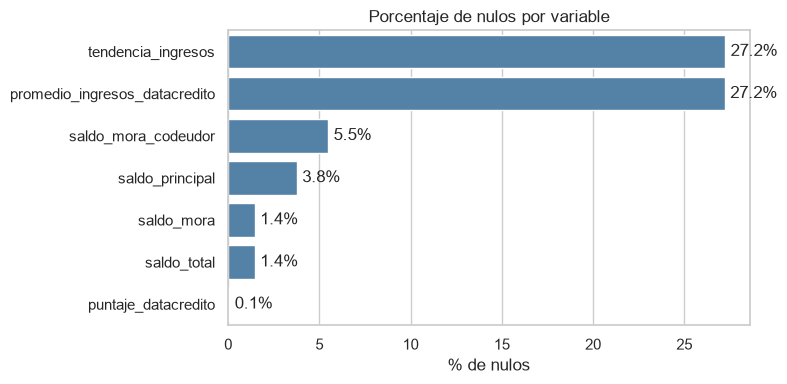

,variable,nulos,%_nulos
21,tendencia_ingresos,2932,27.24
20,promedio_ingresos_datacredito,2930,27.22
16,saldo_mora_codeudor,590,5.48
15,saldo_principal,405,3.76
13,saldo_mora,156,1.45
14,saldo_total,156,1.45
10,puntaje_datacredito,6,0.06


In [7]:
# 4.1 Nulos explícitos (NaN)
nulos = tabla_caract.loc[tabla_caract["nulos"] > 0, ["variable", "nulos", "%_nulos"]]
nulos = nulos.sort_values("%_nulos", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=nulos, x="%_nulos", y="variable", color="steelblue", ax=ax)
ax.set_title("Porcentaje de nulos por variable")
ax.set_xlabel("% de nulos")
ax.set_ylabel("")
for i, v in enumerate(nulos["%_nulos"]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.show()
nulos

Resultado de la grafica: Cada barra es una variable y su largo es el % de registros sin dato. Las dos primeras barras (tendencia_ingresos y promedio_ingresos_datacredito, ~27 %) sobresalen claramente: son las únicas con un volumen de nulos importante. Las demás están por debajo del 6 %, y puntaje_datacredito casi no se ve porque solo le faltan 6 datos. el grafico nos ayuda para decidir como tratar cada variable.

Busca nulos "disfrazados": textos como "NA", "null", "None" o "-" que en realidad significan vacío pero que pandas no reconoce como nulos. Solo revisa las columnas de texto, que son las únicas donde pueden aparecer.

In [8]:
# 4.2 Nulos "disfrazados": textos que en realidad significan vacío
textos_nulos = ["", " ", "NA", "N/A", "na", "nan", "NaN", "null", "NULL", "None", "-", "?"]
columnas_texto = [c for c in df.columns if pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object]
for col in columnas_texto:
    print(f"{col}: {df[col].isin(textos_nulos).sum()} valores tipo texto-nulo")

tipo_laboral: 0 valores tipo texto-nulo
tendencia_ingresos: 0 valores tipo texto-nulo


Revisa tendencia_ingresos, que solo deberí=ia tener 3 categorias (Creciente, Decreciente y Estable). Filtra los valores que no son nulos y que no estan en esa lista, los cuenta y muestra hasta 10 ejemplos.

In [9]:
# 4.3 Valores inválidos en tendencia_ingresos
categorias_validas = ["Creciente", "Decreciente", "Estable"]
invalidos = df.loc[df["tendencia_ingresos"].notna() & ~df["tendencia_ingresos"].isin(categorias_validas),
                   "tendencia_ingresos"]
print(f"Valores inválidos en tendencia_ingresos: {len(invalidos)}")
print("Ejemplos:", list(invalidos.unique()[:10]))

Valores inválidos en tendencia_ingresos: 58
Ejemplos: ['8315', '0', '158042', '3978', '9147', '168750', '-28589', '1000000', '-566272', '24702']


en esta parte simplemente se buscan valores faltantes: como edades matores a 100 anios y cuantas veces aparece cada una, esto con varias variables.

In [10]:
# 4.4 Valores "código" que representan ausencia de dato
print("Edades mayores a 100 años:")
print(df.loc[df["edad_cliente"] > 100, "edad_cliente"].value_counts().sort_index())
print(f"\nSalarios en cero: {(df['salario_cliente'] == 0).sum()}")
print(f"puntaje_datacredito en cero: {(df['puntaje_datacredito'] == 0).sum()}")

Edades mayores a 100 años:
edad_cliente
121      4
122    144
123      2
Name: count, dtype: int64

Salarios en cero: 24
puntaje_datacredito en cero: 145


Unifica los nulos: todo lo que es faltante o inválido pasa a ser np.nan, la forma estándar de representar un dato vacío. Reemplaza los textos-nulo, convierte en nulo cualquier valor de tendencia_ingresos que no sea una de sus 3 categorías, y hace lo mismo con las edades mayores a 100 y los salarios en cero. Al final muestra cómo quedó tendencia_ingresos.

In [11]:
# 4.5 Unificación: todo valor faltante o inválido se representa como np.nan
df = df.replace(textos_nulos, np.nan)
df["tendencia_ingresos"] = df["tendencia_ingresos"].where(
    df["tendencia_ingresos"].isin(categorias_validas), np.nan
)
df.loc[df["edad_cliente"] > 100, "edad_cliente"] = np.nan
df.loc[df["salario_cliente"] == 0, "salario_cliente"] = np.nan

print(df["tendencia_ingresos"].value_counts(dropna=False))

tendencia_ingresos
Creciente      5294
NaN            2990
Decreciente    1291
Estable        1188
Name: count, dtype: int64


Cruza dos preguntas: ¿falta promedio_ingresos_datacredito? y ¿falta tendencia_ingresos? El resultado es una tabla de 2 × 2 que muestra si los nulos de las dos variables ocurren en los mismos clientes.

In [12]:
# ¿Los nulos de las dos variables de ingresos de Datacrédito coinciden?
pd.crosstab(df["promedio_ingresos_datacredito"].isna(), df["tendencia_ingresos"].isna(),
            rownames=["promedio_ingresos nulo"], colnames=["tendencia nulo"])

tendencia nulo,False,True
promedio_ingresos nulo,,
False,7773,60
True,0,2930


**Interpretación:**
- No hay nulos escritos como texto ("NA", "null", etc.). Los nulos explícitos ya venían como vacíos.
- tendencia_ingresos: traía 58 valores numéricos (como 8315 o -28589) que no corresponden a ninguna categoría. Son errores de captura y se convirtieron a "NaN".
- edad_cliente: tiene 150 clientes con 121, 122 o 123 años (144 de ellos con exactamente 122). Es imposible y el valor repetido sugiere un codigo de "dato no disponible", así que se convirtieron a "NaN". Curiosamente, estos clientes tienen una tasa de no pago del 7,3 % (frente al 4,7 % del resto), así que podría valer la pena un indicador "edad_desconocida".
- salario_cliente: tiene 24 salarios en cero. Como un credito no se aprueba sin ingresos, se tratan como dato faltante.
- puntaje_datacredito tiene 145 valores en 0. Probablemente son clientes sin historial crediticio, no un error. No se convierten a nulo aquí; se tratan en la seccion 12 como un atributo propio.
- promedio_ingresos_datacredito y tendencia_ingresos tienen cerca del 27 % de nulos y casi siempre faltan juntas. Corresponden a clientes sin información de ingresos en Datacrédito. No se eliminan: se imputarán en ft_engineering , junto con un indicador sin_info_datacredito.
- Las demás variables con nulos tienen menos del 6 % y se pueden imputar con la mediana.

## 5. Conversion de tipos de datos

Cada columna debe quedar con el tipo que corresponde a su naturaleza:
- tipo_credito y tipo_laboral: como "category".
- tendencia_ingresos: como "categoría ordenada" (Decreciente < Estable < Creciente).
- edad_cliente: como entero que admite nulos (Int64).
- Pago_atiempo: como entero 0/1. Se deja numérica para facilitar el cálculo de tasas y correlaciones.
- fecha_prestamo: como datetime .

In [13]:
df["tipo_credito"] = df["tipo_credito"].astype("category")
df["tipo_laboral"] = df["tipo_laboral"].astype("category")
df["tendencia_ingresos"] = pd.Categorical(
    df["tendencia_ingresos"], categories=["Decreciente", "Estable", "Creciente"], ordered=True
)
df["edad_cliente"] = df["edad_cliente"].astype("Int64")
df["Pago_atiempo"] = df["Pago_atiempo"].astype(int)
df.dtypes

tipo_credito                           category
fecha_prestamo                   datetime64[us]
capital_prestado                        float64
plazo_meses                               int64
edad_cliente                              Int64
tipo_laboral                           category
salario_cliente                         float64
total_otros_prestamos                     int64
cuota_pactada                             int64
puntaje                                 float64
puntaje_datacredito                     float64
cant_creditosvigentes                     int64
huella_consulta                           int64
saldo_mora                              float64
saldo_total                             float64
saldo_principal                         float64
saldo_mora_codeudor                     float64
creditos_sectorFinanciero                 int64
creditos_sectorCooperativo                int64
creditos_sectorReal                       int64
promedio_ingresos_datacredito           

## 6. Eliminación de variables irrelevantes

Se revisan dos tipos de variables que no deben entrar al modelo:
1. Variables con **fuga de información** (*data leakage*), que contienen la respuesta.
2. Variables **casi constantes**, que no aportan información.

In [14]:
# 6.1 Fuga de información en "puntaje"
df.groupby("Pago_atiempo")["puntaje"].agg(["count", "min", "max", "mean", "median"])

,count,min,max,mean,median
Pago_atiempo,,,,,
0,511,-38.01,62.67,23.09,25.42
1,10252,63.81,95.23,94.56,95.23


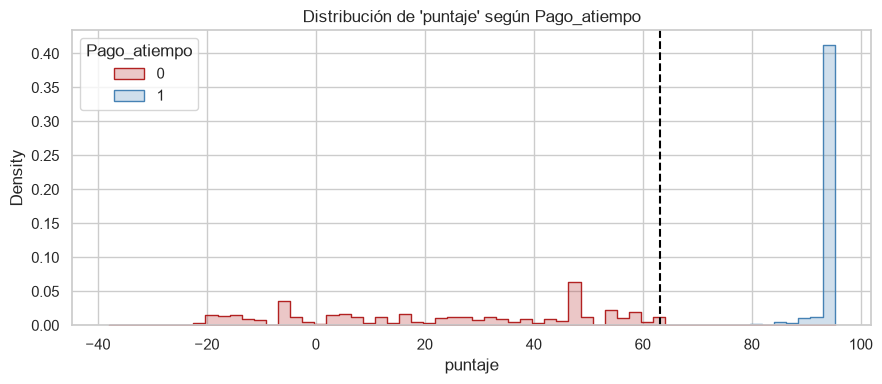

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x="puntaje", hue="Pago_atiempo", bins=60, palette=COLORES_OBJETIVO,
             element="step", stat="density", common_norm=False, ax=ax)
ax.axvline(63.2, color="black", linestyle="--", label="Corte ≈ 63")
ax.set_title("Distribución de 'puntaje' según Pago_atiempo")
plt.tight_layout()
plt.show()

**Interpretación:** puntaje separa perfectamente la variable objetivo:
- Todos los que no pagaron tienen puntaje entre -38,01 y 62,67.
- Todos los que si pagaron tienen puntaje entre 63,81 y 95,23.

Ninguna variable real predice con 100 % de exactitud. Lo más probable es que el puntaje se calculó conociendo el comportamiento de pago, así que no estaría disponible al momento de aprobar un crédito nuevo. Si se deja, el modelo tendría un desempeño perfecto en el entrenamiento y fallaría en producción. "Se elimina".

para cada columna calcula cual es el valor mas frecuente y que registros ocupa. por ejemplo solo va a mostrar las variables mas constantes para saber cuales aportan o no al analisis.

In [16]:
# 6.2 Variables casi constantes: % que ocupa el valor más frecuente
dominancia = pd.DataFrame({
    "valor_mas_frecuente": df.apply(lambda s: s.mode(dropna=True).iloc[0]),
    "%_valor_mas_frecuente": df.apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100).round(2),
}).sort_values("%_valor_mas_frecuente", ascending=False)
dominancia.head(6)

,valor_mas_frecuente,%_valor_mas_frecuente
saldo_mora_codeudor,0.00,99.97
saldo_mora,0.00,99.48
Pago_atiempo,1,95.25
puntaje,95.23,87.40
creditos_sectorCooperativo,0,82.39
tipo_credito,4,71.98


aca se cuenta cuantas veces aparece cada valor de saldo_mora_codeudor

In [17]:
print(df["saldo_mora_codeudor"].value_counts(dropna=False))

saldo_mora_codeudor
0.00        10170
NaN           590
30.00           1
470.00          1
2,145.00        1
Name: count, dtype: int64


**Interpretación:**
- saldo_mora_codeudor: casi todos los valores son 0 y solo hay 3 registros distintos de cero (30, 470 y 2.145 pesos). No aporta información. **Se elimina.
- Pago_atiempo: aparece arriba porque esta desbalanceada (95 % son 1), pero es la variable objetivo, así que se conserva.
- saldo_mora: también es casi siempre 0 (99,5 %), pero no se elimina: en la seccion 8 se ve que los pocos clientes con mora tienen una tasa de no pago mucho más alta. Se transformará en el indicador tiene_mora.
- creditos_sectorCooperativo: tiene un 82 % de ceros, pero conserva variación, así que se mantiene.

se hace la eliminacion de las dos variables y muestra cuantas columnas quedan

In [18]:
variables_eliminadas = ["puntaje", "saldo_mora_codeudor"]
df = df.drop(columns=variables_eliminadas)
print(f"Variables eliminadas: {variables_eliminadas}")
print(f"Dimensiones finales: {df.shape}")

Variables eliminadas: ['puntaje', 'saldo_mora_codeudor']
Dimensiones finales: (10763, 21)


# Parte B: exploración de datos y descripción (EDA)

## 7. Análisis univariable

### 7.1 Variable objetivo

Cuenta cuantos creditos hay en cada clase de la variable objetivo, calcula el porcentaje y arma una tabla con nombres claros. Luego dibuja un gráfico de barras con la cantidad y el porcentaje escritos encima de cada barra.

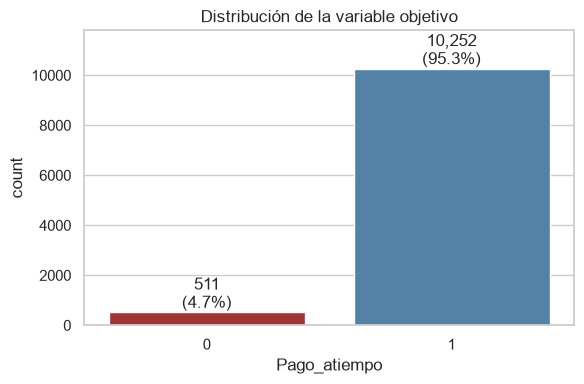

,cantidad,porcentaje_%
0 = No pagó a tiempo,511,4.75
1 = Pagó a tiempo,10252,95.25


In [19]:
conteo_obj = df["Pago_atiempo"].value_counts().sort_index()
tabla_obj = pd.DataFrame({"cantidad": conteo_obj,
                          "porcentaje_%": (conteo_obj / len(df) * 100).round(2)})
tabla_obj.index = ["0 = No pagó a tiempo", "1 = Pagó a tiempo"]

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Pago_atiempo", hue="Pago_atiempo", palette=COLORES_OBJETIVO, legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}\n({p.get_height() / len(df):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Distribución de la variable objetivo")
ax.set_ylim(0, conteo_obj.max() * 1.15)
plt.tight_layout()
plt.show()
tabla_obj

Interpretación: la variable objetivo está muy desbalanceada: el 95,25 % de los créditos se pagaron a tiempo y solo el 4,75 % (511 créditos) no.

Consecuencias para el modelado:
- Un modelo que siempre prediga "paga a tiempo" tendría un 95 % de accuracy sin servir para nada. Por eso hay que evaluar con recall, precision, F1 y ROC-AUC sobre la clase 0.
- En train_test_split hay que usar stratify=y para conservar la proporción.
- Se puede compensar el desbalance con class_weight="balanced" o con técnicas de remuestreo (SMOTE).

### 7.2 Variables numéricas: descripción estadística

en esta parte se arma la lista de variables numéricas (sin contar la objetivo), que se reutiliza en el resto del análisis, y aplica describe(), que calcula para cada una: cantidad de datos, media, desviación estándar, mínimo, cuartiles (25 %, 50 % y 75 %) y máximo.

In [20]:
variables_numericas = [c for c in df.select_dtypes(include="number").columns if c != "Pago_atiempo"]
df[variables_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
capital_prestado,"10,763.00","2,434,315.00","1,909,642.76","360,000.00","1,224,831.00","1,921,920.00","3,084,840.00","41,444,152.80"
plazo_meses,"10,763.00",10.58,6.63,2.00,6.00,10.00,12.00,90.00
edad_cliente,"10,613.00",42.85,11.95,19.00,33.00,42.00,52.00,69.00
salario_cliente,"10,739.00","17,254,907.51","355,872,817.68","1,000.00","2,000,000.00","3,000,000.00","4,900,000.00","22,000,000,000.00"
total_otros_prestamos,"10,763.00","6,238,869.65","118,418,316.94",0.00,"500,000.00","1,000,000.00","2,000,000.00","6,787,675,263.00"
cuota_pactada,"10,763.00","243,617.41","210,493.69","23,944.00","121,041.50","182,863.00","287,833.50","3,816,752.00"
puntaje_datacredito,"10,757.00",780.79,104.88,-7.00,757.00,791.00,825.00,999.00
cant_creditosvigentes,"10,763.00",5.73,3.98,0.00,3.00,5.00,8.00,62.00
huella_consulta,"10,763.00",4.23,3.06,0.00,2.00,4.00,6.00,29.00
saldo_mora,"10,607.00",7.75,225.96,0.00,0.00,0.00,0.00,"12,534.00"


en esta parte se calcula descripcion estadisitca completa de cada variables numerica . la funcion resumen estadistico obteine medidas de tendecias central moda , mediana moda , de poscion y dispesion (minimo , maximo , rango , cuartiles , IQR ... etc) tambien aplica la prueba de normalidad. si p < 0,05 la variables es normal)  y la funciona clasificar distribucion usa la simetria y la propocion de ceros para etiquetar cada variables como gaussiana, uniforme, log-normal, asimétrica o concentrada en cero.

In [21]:
def clasificar_distribucion(serie: pd.Series) -> str:
    """Clasifica la forma de la distribución según asimetría, curtosis y proporción de ceros."""
    s = serie.dropna().astype(float)
    asimetria, curtosis = s.skew(), s.kurt()
    if (s == 0).mean() > 0.5:
        return "Concentrada en cero"
    if abs(asimetria) < 0.5 and abs(curtosis) < 1:
        return "Aprox. gaussiana"
    if curtosis < -1:
        return "Aprox. uniforme"
    if asimetria > 1 and s.min() >= 0 and abs(np.log1p(s).skew()) < 0.75:
        return "Asimétrica positiva (aprox. log-normal)"
    if asimetria > 1:
        return "Asimétrica positiva (cola larga)"
    if asimetria < -1:
        return "Asimétrica negativa"
    return "Moderadamente asimétrica"


def resumen_estadistico(data: pd.DataFrame, columnas: list) -> pd.DataFrame:
    """Tendencia central, dispersión y forma de cada variable numérica."""
    filas = []
    for col in columnas:
        s = data[col].dropna().astype(float)
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        atipicos = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100
        filas.append({
            "variable": col,
            "media": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0],
            "min": s.min(), "max": s.max(), "rango": s.max() - s.min(),
            "Q1": q1, "Q3": q3, "IQR": iqr,
            "varianza": s.var(), "desv_estandar": s.std(),
            "coef_variacion_%": s.std() / s.mean() * 100 if s.mean() != 0 else np.nan,
            "skewness": s.skew(), "kurtosis": s.kurt(),
            "%_atipicos_IQR": atipicos,
            "p_valor_normalidad": stats.normaltest(s).pvalue,
            "distribucion": clasificar_distribucion(s),
        })
    return pd.DataFrame(filas).set_index("variable")


resumen_num = resumen_estadistico(df, variables_numericas)
resumen_num

,media,mediana,moda,min,max,rango,Q1,Q3,IQR,varianza,desv_estandar,coef_variacion_%,skewness,kurtosis,%_atipicos_IQR,p_valor_normalidad,distribucion
variable,,,,,,,,,,,,,,,,,
capital_prestado,"2,434,315.00","1,921,920.00","1,200,000.00","360,000.00","41,444,152.80","41,084,152.80","1,224,831.00","3,084,840.00","1,860,009.00","3,646,735,466,988.66","1,909,642.76",78.45,3.72,35.32,5.11,0.00,Asimétrica positiva (aprox. log-normal)
plazo_meses,10.58,10.00,6.00,2.00,90.00,88.00,6.00,12.00,6.00,43.98,6.63,62.71,2.46,7.78,8.07,0.00,Asimétrica positiva (aprox. log-normal)
edad_cliente,42.85,42.00,40.00,19.00,69.00,50.00,33.00,52.00,19.00,142.74,11.95,27.88,0.27,-0.86,0.00,0.00,Aprox. gaussiana
salario_cliente,"17,254,907.51","3,000,000.00","3,000,000.00","1,000.00","22,000,000,000.00","21,999,999,000.00","2,000,000.00","4,900,000.00","2,900,000.00","126,645,462,365,504,336.00","355,872,817.68","2,062.44",43.73,"2,206.30",6.67,0.00,Asimétrica positiva (cola larga)
total_otros_prestamos,"6,238,869.65","1,000,000.00","2,000,000.00",0.00,"6,787,675,263.00","6,787,675,263.00","500,000.00","2,000,000.00","1,500,000.00","14,022,897,787,155,472.00","118,418,316.94","1,898.07",38.46,"1,719.28",5.47,0.00,Asimétrica positiva (cola larga)
cuota_pactada,"243,617.41","182,863.00","205,990.00","23,944.00","3,816,752.00","3,792,808.00","121,041.50","287,833.50","166,792.00","44,307,595,469.58","210,493.69",86.40,3.79,26.65,7.11,0.00,Asimétrica positiva (aprox. log-normal)
puntaje_datacredito,780.79,791.00,0.00,-7.00,999.00,"1,006.00",757.00,825.00,68.00,"10,999.40",104.88,13.43,-5.64,39.44,1.82,0.00,Asimétrica negativa
cant_creditosvigentes,5.73,5.00,4.00,0.00,62.00,62.00,3.00,8.00,5.00,15.82,3.98,69.45,1.80,8.62,2.25,0.00,Asimétrica positiva (aprox. log-normal)
huella_consulta,4.23,4.00,2.00,0.00,29.00,29.00,2.00,6.00,4.00,9.39,3.06,72.48,1.49,4.00,2.01,0.00,Asimétrica positiva (aprox. log-normal)


In [22]:
# Vista resumida de la forma de cada distribución
resumen_num[["skewness", "kurtosis", "%_atipicos_IQR", "p_valor_normalidad", "distribucion"]].round(3)

,skewness,kurtosis,%_atipicos_IQR,p_valor_normalidad,distribucion
variable,,,,,
capital_prestado,3.72,35.32,5.11,0.00,Asimétrica positiva (aprox. log-normal)
plazo_meses,2.46,7.78,8.07,0.00,Asimétrica positiva (aprox. log-normal)
edad_cliente,0.27,-0.86,0.00,0.00,Aprox. gaussiana
salario_cliente,43.73,"2,206.30",6.67,0.00,Asimétrica positiva (cola larga)
total_otros_prestamos,38.46,"1,719.28",5.47,0.00,Asimétrica positiva (cola larga)
cuota_pactada,3.79,26.65,7.11,0.00,Asimétrica positiva (aprox. log-normal)
puntaje_datacredito,-5.64,39.44,1.82,0.00,Asimétrica negativa
cant_creditosvigentes,1.80,8.62,2.25,0.00,Asimétrica positiva (aprox. log-normal)
huella_consulta,1.49,4.00,2.01,0.00,Asimétrica positiva (aprox. log-normal)


**Interpretación de la descripción estadística:**

- **Ninguna variable es estrictamente normal (gaussiana).** La prueba de normalidad de D'Agostino da un p-valor ≈ 0 en todas, así que se rechaza la normalidad. Esto es típico en datos financieros. La más cercana es edad_cliente: después de eliminar las edades imposibles, tiene *skewness* de 0,27 y *kurtosis* de -0,86, una forma aproximadamente gaussiana. La prueba la rechaza igual, porque con más de 10.000 datos detecta hasta desviaciones pequeñas.
- **Tendencia central:** en casi todas las variables de dinero la media es mucho mayor que la mediana, señal de asimetría a la derecha. Por ejemplo, el salario_cliente medio supera los 17 millones, mientras que la mediana es de 3 millones, porque unos pocos valores enormes jalan el promedio. Por eso, la mediana representa mejor al cliente típico: un préstamo de ~1,9 millones, a 10 meses, con una cuota de ~183 mil pesos y un cliente de 42 años.
- **Dispersión:** salario_cliente, total_otros_prestamos y saldo_total tienen *skewness* > 20 y *kurtosis* > 700. Son colas extremadamente largas: el salario llega a 22.000 millones y los otros préstamos a 6.787 millones, valores muy poco creíbles.
- **Tipos de distribución:**
  - capital_prestado y cuota_pactada son aproximadamente log-normales: al aplicarles logaritmo quedan casi simétricas. Esto sugiere la transformación log1p.
  - cant_creditosvigentes, huella_consulta y los créditos por sector son conteos asimétricos a la derecha, con forma parecida a una Poisson. La función los marca como "aprox. log-normal" porque el logaritmo los vuelve simétricos, pero por ser conteos se describen mejor como Poisson.
  -saldo_mora y creditos_sectorCooperativo están concentradas en cero.
  - puntaje_datacredito: es asimétrica negativa por los 145 clientes con puntaje 0. Sin ellos, se concentra entre 750 y 830.
  - plazo_meses es discreta y multimodal: se concentra en plazos "redondos" (6, 10, 12, 24 y 36 meses).
- Atípicos: varias variables tienen entre el 5 % y el 10 % de valores fuera del rango IQR. No todos son errores (hay créditos realmente grandes), pero los extremos se deben limitar (*winsorizar*) o transformar con logaritmo.

### 7.3 Variables numéricas: histogramas

 Dibuja un histograma por cada variable numérica, en una cuadrícula de 4 × 4, con una línea roja punteada en la media y una línea verde en la mediana.

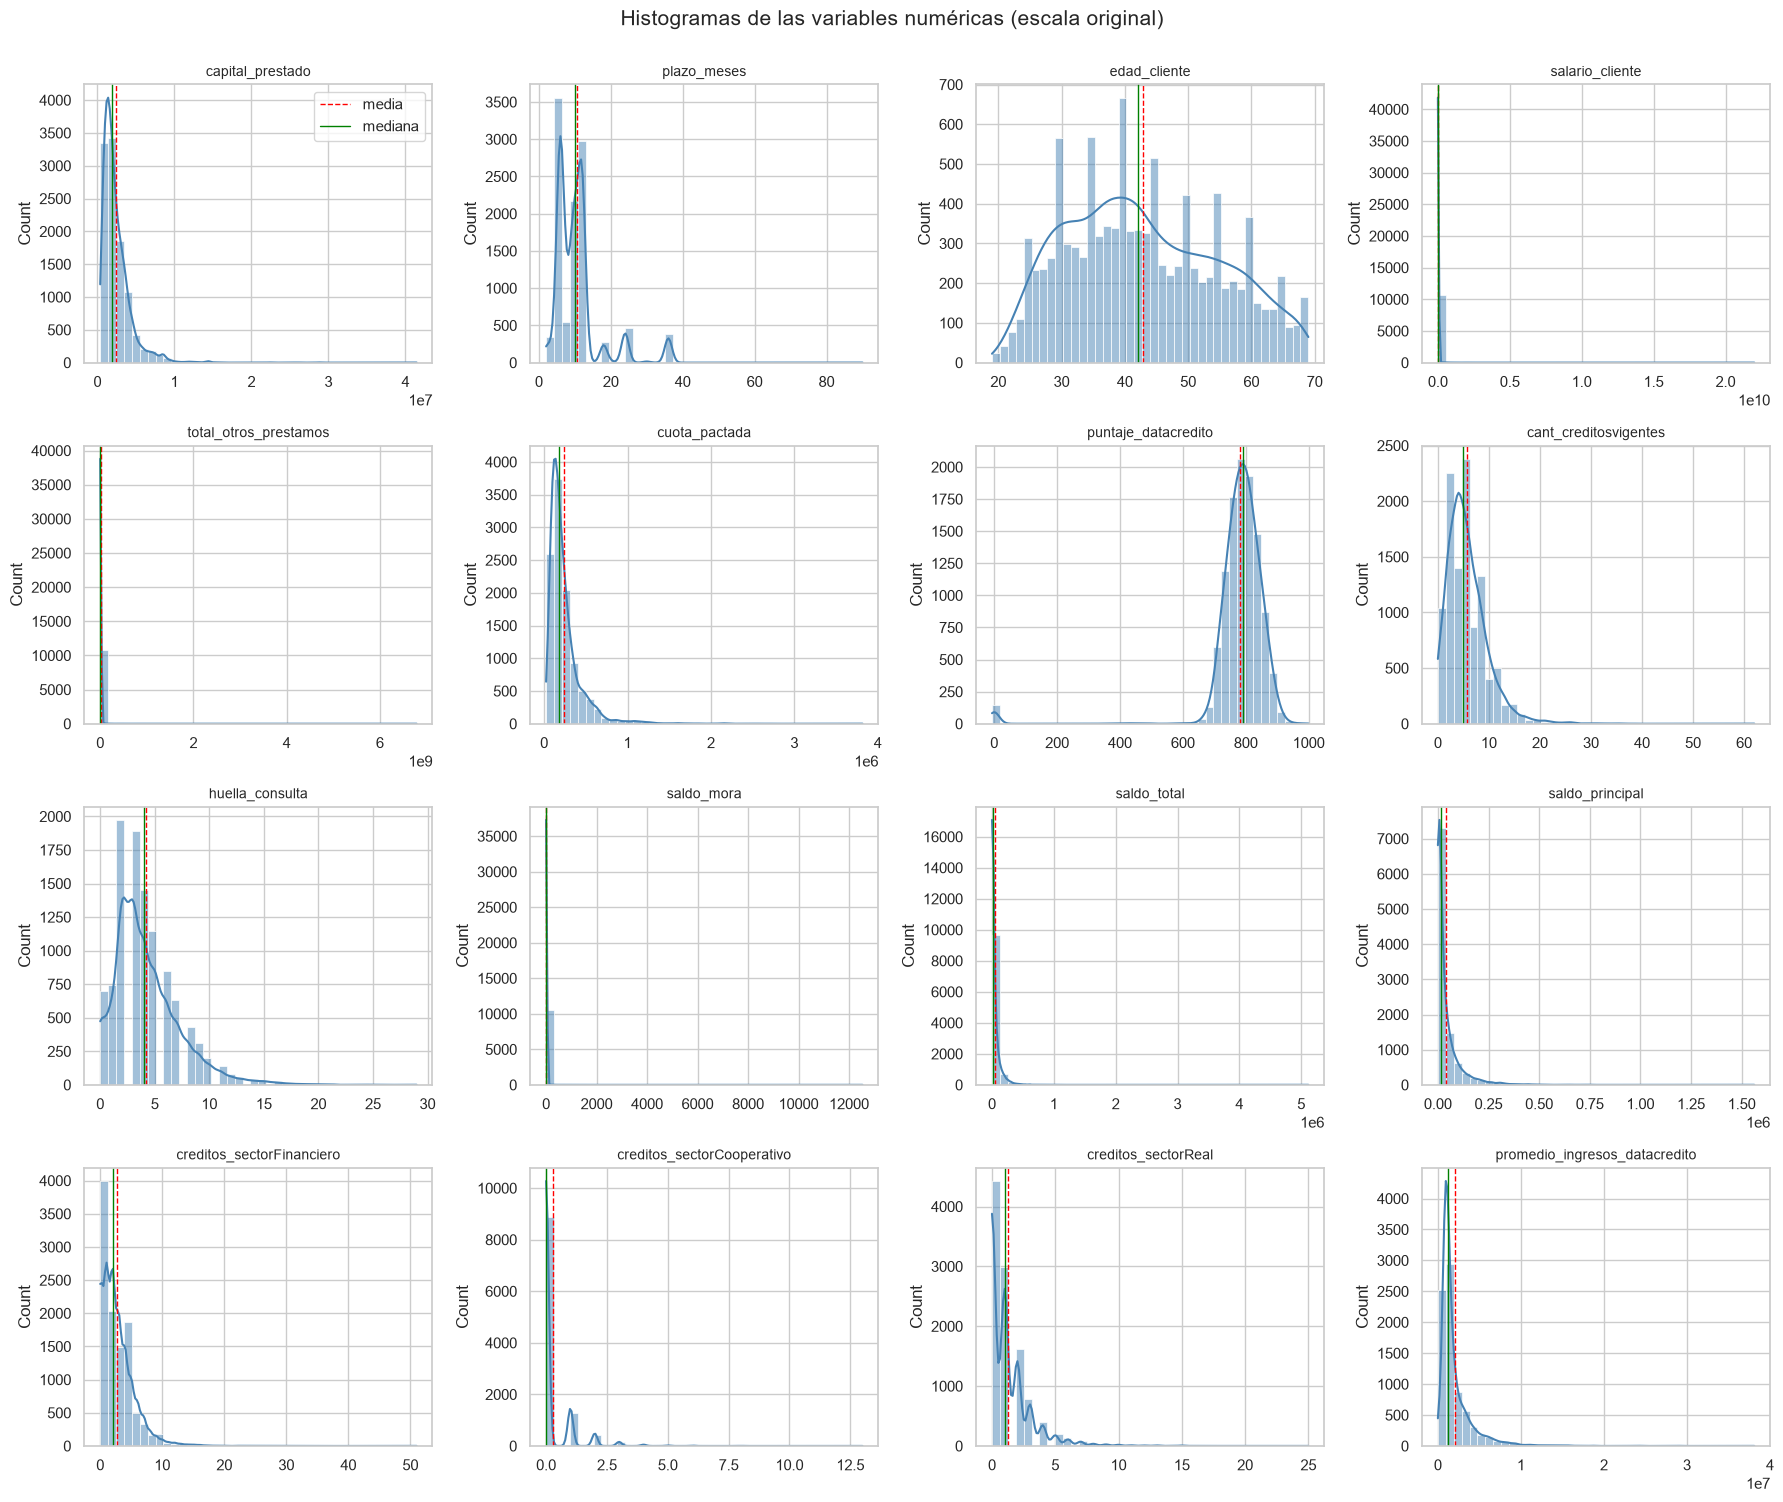

In [23]:
fig, axes = plt.subplots(4, 4, figsize=(18, 15))
for ax, col in zip(axes.flat, variables_numericas):
    sns.histplot(df[col].dropna().astype(float), bins=40, kde=True, color="steelblue", ax=ax)
    ax.axvline(df[col].mean(), color="red", linestyle="--", linewidth=1, label="media")
    ax.axvline(df[col].median(), color="green", linestyle="-", linewidth=1, label="mediana")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
axes.flat[0].legend()
for ax in axes.flat[len(variables_numericas):]:
    ax.set_visible(False)
plt.suptitle("Histogramas de las variables numéricas (escala original)", fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

En escala original, las variables de dinero quedan "aplastadas" contra el eje porque unos pocos valores extremos estiran el gráfico. Para ver su forma real, se grafican con escala logarítmica:

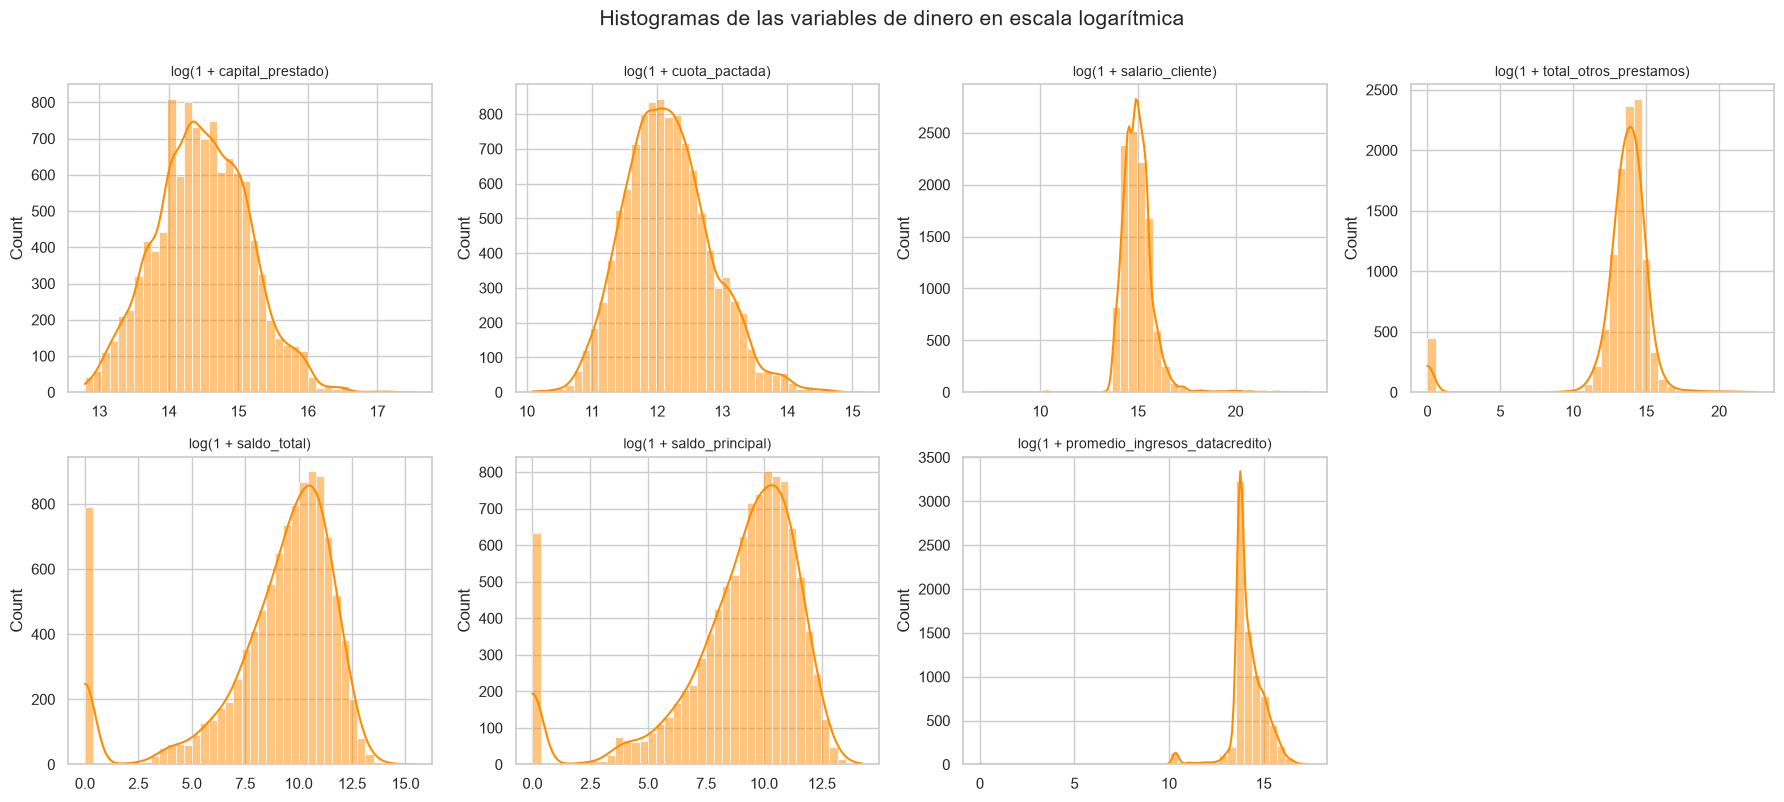

In [24]:
variables_dinero = ["capital_prestado", "cuota_pactada", "salario_cliente", "total_otros_prestamos",
                    "saldo_total", "saldo_principal", "promedio_ingresos_datacredito"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, variables_dinero):
    sns.histplot(np.log1p(df[col].dropna().astype(float)), bins=40, kde=True, color="darkorange", ax=ax)
    ax.set_title(f"log(1 + {col})", fontsize=10)
    ax.set_xlabel("")
axes.flat[-1].set_visible(False)
plt.suptitle("Histogramas de las variables de dinero en escala logarítmica", fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

**Interpretación:** con logaritmo, `capital_prestado`, `cuota_pactada` y `promedio_ingresos_datacredito` toman una forma de campana, lo que confirma que son **aproximadamente log-normales**. En `saldo_total` y `saldo_principal` aparece un pico separado en 0 (clientes sin saldo), así que son mezclas de "sin deuda" y "con deuda". Para modelos lineales conviene aplicar `log1p` a estas variables.

### 7.4 Variables numéricas: diagramas de caja (boxplots)

Dibuja un diagrama de caja (boxplot) horizontal por cada variable numérica, en una cuadrícula de 4 × 4.

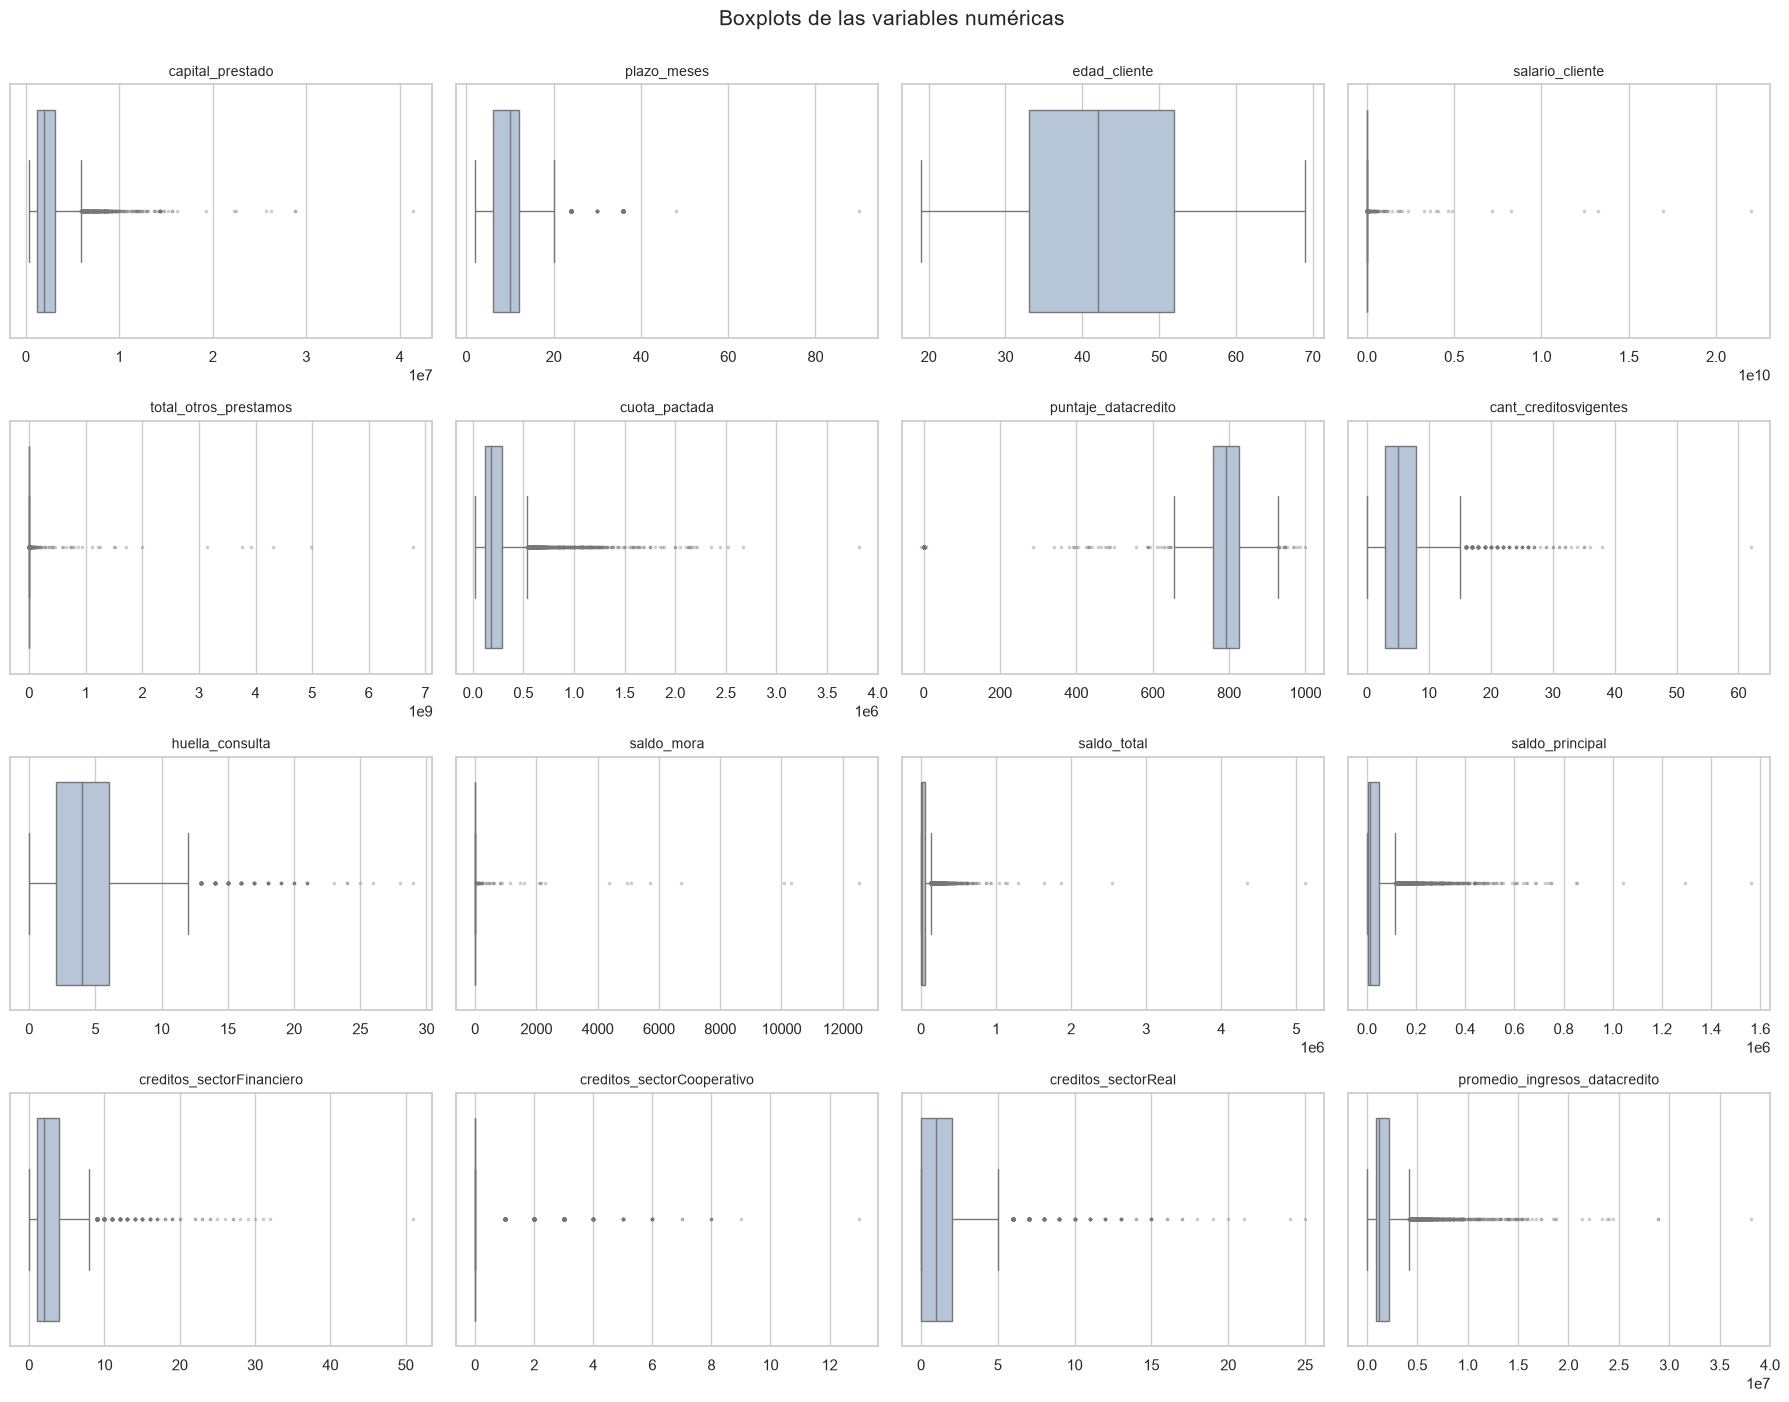

In [25]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, variables_numericas):
    sns.boxplot(x=df[col].dropna().astype(float), color="lightsteelblue", ax=ax,
                flierprops={"marker": ".", "markersize": 3, "alpha": 0.4})
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
for ax in axes.flat[len(variables_numericas):]:
    ax.set_visible(False)
plt.suptitle("Boxplots de las variables numéricas", fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

todas las variables de dinero y de conteo tienen muchos puntos por fuera de los bigotes, todos hacia la derecha. Algunos son plausibles (por ejemplo, créditos grandes de 41 millones), pero otros son claramente errores, como salarios de miles de millones o 62 créditos vigentes. edad_cliente ya no muestra los valores de 122 años porque se convirtieron a nulos en la sección 4. Estos hallazgos alimentan las reglas de validación de la sección 10.

### 7.5 Variables numéricas: tablas pivote

tabla pivote con una fila por tipo de crédito: muestra cuántos créditos hay de cada tipo y la mediana del capital, la cuota, la edad y el plazo. Sirve para comparar las condiciones de cada tipo de crédito.

In [26]:
pd.pivot_table(df, index="tipo_credito", values=["capital_prestado", "plazo_meses", "cuota_pactada", "edad_cliente"],
               aggfunc=["count", "median"], observed=True)

count                                         \
             capital_prestado cuota_pactada edad_cliente plazo_meses   
tipo_credito                                                           
4                        7747          7747         7745        7747   
6                          21            21           21          21   
7                           2             2            2           2   
9                        2876          2876         2728        2876   
10                        116           116          116         116   
68                          1             1            1           1   

                       median                                         
             capital_prestado cuota_pactada edad_cliente plazo_meses  
tipo_credito                                                          
4                1,929,896.40    176,918.00        41.00       10.00  
6                2,309,859.60    149,969.00        35.00       12.00  
7                8,117,211.60    276,845.00        35.50       50.00  
9                1,892,546.40    204,382.00        42.00       10.00  
10               2,328,660.00    189,528.50        43.50       12.00  
68               2,822,823.60     49,007.00        29.00       48.00

In [27]:
pd.pivot_table(df, index="tipo_laboral", values=["capital_prestado", "salario_cliente", "puntaje_datacredito",
                                                 "huella_consulta", "cant_creditosvigentes"],
               aggfunc="median", observed=True)

,cant_creditosvigentes,capital_prestado,huella_consulta,puntaje_datacredito,salario_cliente
tipo_laboral,,,,,
Empleado,5.00,"1,951,365.00",4.00,789.00,"2,700,000.00"
Independiente,5.00,"1,872,000.00",4.00,794.00,"3,800,000.00"


**Interpretación:**
- Los tipos de crédito 4 y 9 concentran el 98 % de los registros y tienen condiciones parecidas (capital mediano de ~1,9 millones a 10 meses). Los tipos 7 y 68 son créditos más grandes y a plazos mucho más largos (48 a 50 meses), pero solo tienen 1 o 2 registros.
- Los independientes declaran un salario mediano mayor (3,8 millones) que los empleados (2,7 millones), pero piden montos parecidos y tienen el mismo número de créditos vigentes y de consultas. Su puntaje de Datacrédito también es similar (794 frente a 789).

### 7.6 Variables categóricas: value_counts y countplots

Para cada variable categórica cuenta cuántos registros hay en cada categoría (incluyendo los nulos) y qué porcentaje representan.

In [28]:
variables_categoricas = ["tipo_credito", "tipo_laboral", "tendencia_ingresos"]
for col in variables_categoricas:
    tabla = pd.DataFrame({
        "cantidad": df[col].value_counts(dropna=False),
        "porcentaje_%": (df[col].value_counts(dropna=False, normalize=True) * 100).round(2),
    })
    print(f"===== {col} =====")
    display(tabla)

===== tipo_credito =====


,cantidad,porcentaje_%
tipo_credito,,
4,7747,71.98
9,2876,26.72
10,116,1.08
6,21,0.20
7,2,0.02
68,1,0.01


===== tipo_laboral =====


,cantidad,porcentaje_%
tipo_laboral,,
Empleado,6754,62.75
Independiente,4009,37.25


===== tendencia_ingresos =====


,cantidad,porcentaje_%
tendencia_ingresos,,
Creciente,5294,49.19
NaN,2990,27.78
Decreciente,1291,11.99
Estable,1188,11.04


Dibuja un gráfico de conteo (countplot) por cada variable categórica, con las barras ordenadas de la categoría más frecuente a la menos frecuente y la cantidad escrita encima. Los nulos aparecen como "Sin dato".

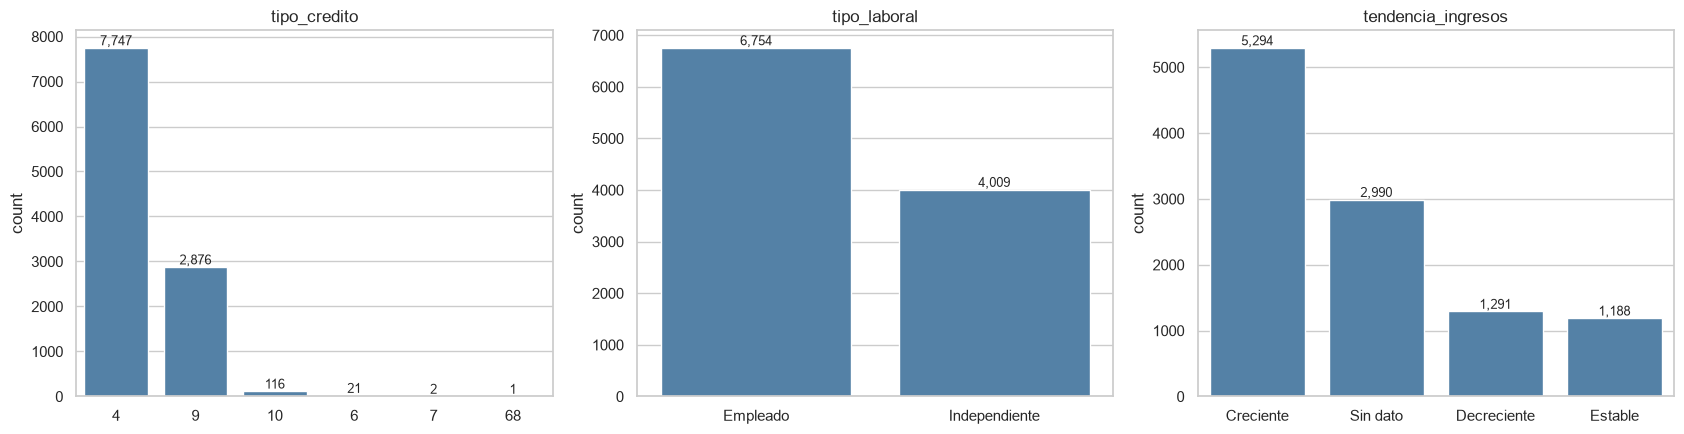

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, variables_categoricas):
    datos = con_sin_dato(df[col])
    orden = datos.value_counts().index
    sns.countplot(x=datos, order=orden, color="steelblue", ax=ax)
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Tabla pivote que cruza dos categóricas: cuántos créditos hay de cada combinación de tipo laboral (filas) y tendencia de ingresos (columnas), con totales.

In [30]:
# Tabla pivote entre variables categóricas
pd.pivot_table(df.assign(tendencia=con_sin_dato(df["tendencia_ingresos"])),
               index="tipo_laboral", columns="tendencia", values="Pago_atiempo",
               aggfunc="count", margins=True, margins_name="Total", observed=True)

tendencia,Creciente,Decreciente,Estable,Sin dato,Total
tipo_laboral,,,,,
Empleado,3843,937,646,1328,6754
Independiente,1451,354,542,1662,4009
Total,5294,1291,1188,2990,10763


**Interpretación:**
-tipo_credito: el tipo 4 (72 %) y el tipo 9 (26,7 %) dominan. Los tipos 10 (116), 6 (21), 7 (2) y 68 (1) son categorías raras. Con tan pocos casos, un modelo no puede aprender de ellas y además pueden no aparecer en el conjunto de prueba. Conviene agruparlas en "Otros".
-tipo_laboral: el 62,8 % son empleados y el 37,2 % independientes. Está razonablemente balanceada.
-tendencia_ingresos: predomina "Creciente" (49 %). El 27,8 % no tiene dato, por lo que "Sin dato" se puede manejar como una categoría más.

### 7.7 Variable temporal

Agrupa los créditos por mes de desembolso, cuenta cuántos hay en cada mes y dibuja la evolución en un gráfico de línea.

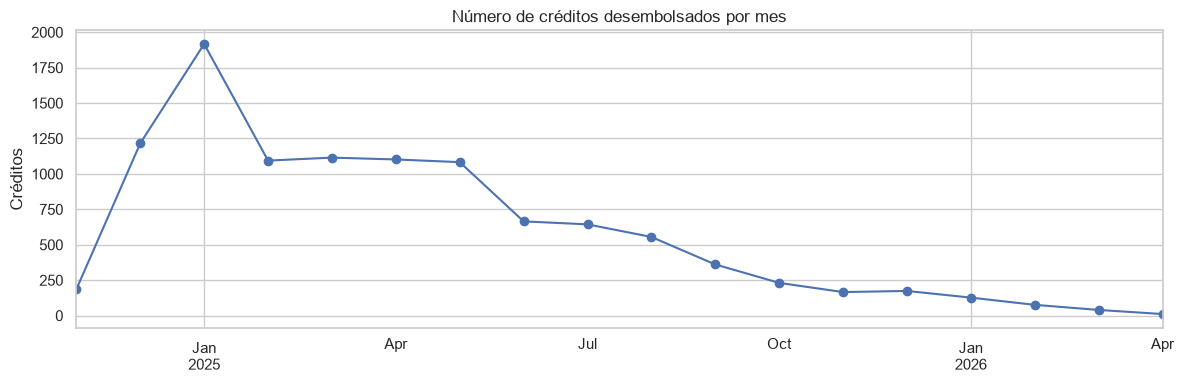

In [31]:
creditos_mes = df.set_index("fecha_prestamo").resample("MS")["Pago_atiempo"].count()
fig, ax = plt.subplots(figsize=(12, 4))
creditos_mes.plot(marker="o", ax=ax)
ax.set_title("Número de créditos desembolsados por mes")
ax.set_xlabel("")
ax.set_ylabel("Créditos")
plt.tight_layout()
plt.show()

 el volumen de créditos se concentra entre diciembre de 2024 y mayo de 2025 y luego cae con fuerza. Los últimos meses (2026) tienen muy pocos registros. Esto es importante para el monitoreo: si la población de clientes cambia con el tiempo, el modelo puede perder desempeño (data drift).

## 8. Análisis bivariable (frente a la variable objetivo)

En adelante se usa la tasa de no pago (% de créditos con Pago_atiempo = 0), porque es más fácil de interpretar que la tasa de pago. La tasa general es del 4,75 %.

Calcula la tasa general de no pago (el % de créditos con Pago_atiempo = 0) y define la función tasa_no_pago, que se usa en todo el análisis bivariable: dada una columna, agrupa los créditos por sus valores y devuelve, para cada grupo, cuántos créditos tiene y qué % no pagó a tiempo

In [32]:
TASA_GENERAL = (1 - df["Pago_atiempo"].mean()) * 100


def tasa_no_pago(data: pd.DataFrame, columna) -> pd.DataFrame:
    """Cantidad de créditos y % de no pago por cada grupo de 'columna'."""
    return (data.groupby(columna, observed=True, dropna=False)["Pago_atiempo"]
                .agg(creditos="count", tasa_no_pago_pct=lambda s: (1 - s.mean()) * 100)
                .round(2))


print(f"Tasa general de no pago: {TASA_GENERAL:.2f}%")

Tasa general de no pago: 4.75%


### 8.1 Variables numéricas frente a Pago_atiempo

Compara cada variable numérica entre quienes pagaron y quienes no: calcula la mediana y la media de cada grupo y aplica la prueba de Mann-Whitney, que dice si las dos distribuciones son diferentes. Se usa esta prueba porque no exige que los datos sean normales. Si p < 0,05, la diferencia es estadísticamente significativa. La tabla queda ordenada de la variable más significativa a la menos.

In [33]:
filas = []
for col in variables_numericas:
    no_paga = df.loc[df["Pago_atiempo"] == 0, col].dropna().astype(float)
    paga = df.loc[df["Pago_atiempo"] == 1, col].dropna().astype(float)
    p_valor = stats.mannwhitneyu(no_paga, paga).pvalue
    filas.append({"variable": col,
                  "mediana_no_paga": no_paga.median(), "mediana_paga": paga.median(),
                  "media_no_paga": no_paga.mean(), "media_paga": paga.mean(),
                  "p_valor_mann_whitney": p_valor,
                  "diferencia_significativa": "Sí" if p_valor < 0.05 else "No"})
comparacion_num = pd.DataFrame(filas).set_index("variable").sort_values("p_valor_mann_whitney")
comparacion_num

,mediana_no_paga,mediana_paga,media_no_paga,media_paga,p_valor_mann_whitney,diferencia_significativa
variable,,,,,,
saldo_mora,0.00,0.00,82.37,4.05,0.00,Sí
puntaje_datacredito,768.00,792.00,748.88,782.38,0.00,Sí
huella_consulta,5.00,4.00,5.24,4.18,0.00,Sí
edad_cliente,37.00,42.00,40.01,42.99,0.00,Sí
promedio_ingresos_datacredito,"1,052,529.00","1,211,296.00","1,605,742.05","2,023,447.77",0.00,Sí
capital_prestado,"2,268,000.00","1,908,446.40","2,781,774.11","2,416,996.27",0.00,Sí
creditos_sectorFinanciero,2.00,2.00,2.52,2.79,0.00,Sí
total_otros_prestamos,"900,000.00","1,000,000.00","11,564,401.93","5,973,424.18",0.01,Sí
creditos_sectorCooperativo,0.00,0.00,0.20,0.27,0.01,Sí


Dibuja, para cada variable numérica, dos cajas lado a lado: una para quienes no pagaron (0) y otra para quienes pagaron (1). Los atípicos se ocultan para que las cajas se vean bien.

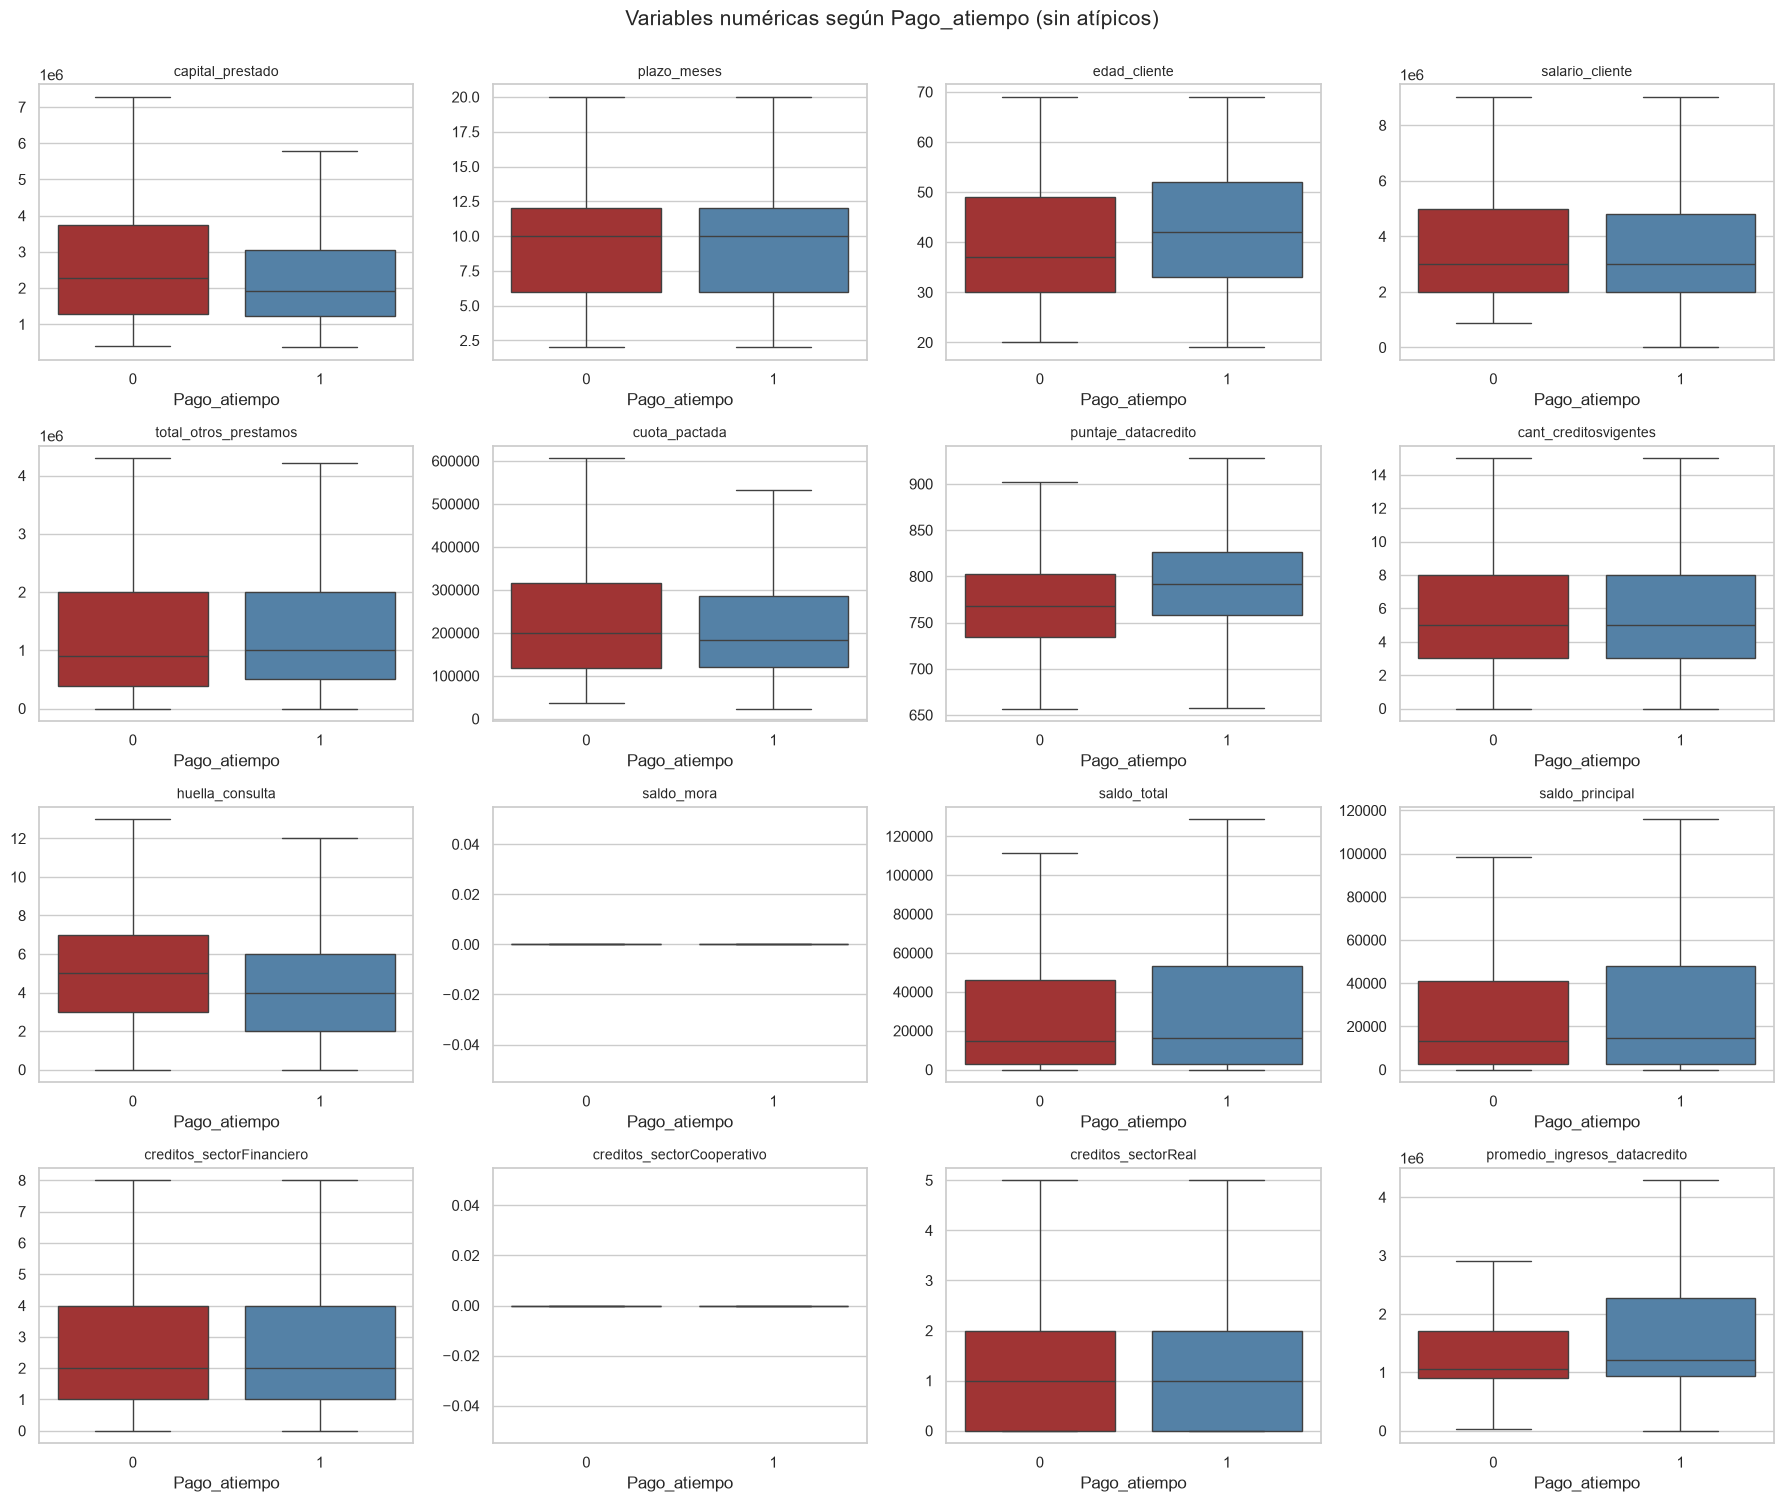

In [34]:
fig, axes = plt.subplots(4, 4, figsize=(18, 15))
for ax, col in zip(axes.flat, variables_numericas):
    datos = df[[col, "Pago_atiempo"]].dropna().astype({col: float})
    sns.boxplot(data=datos, x="Pago_atiempo", y=col, hue="Pago_atiempo", palette=COLORES_OBJETIVO,
                legend=False, showfliers=False, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Pago_atiempo")
    ax.set_ylabel("")
for ax in axes.flat[len(variables_numericas):]:
    ax.set_visible(False)
plt.suptitle("Variables numéricas según Pago_atiempo (sin atípicos)", fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

Divide 6 variables numéricas clave en quintiles (5 grupos con la misma cantidad de créditos, de los valores más bajos a los más altos) y calcula la tasa de no pago de cada quintil con tasa_no_pago. Cada variable se dibuja como un gráfico de barras con la tasa general como línea de referencia

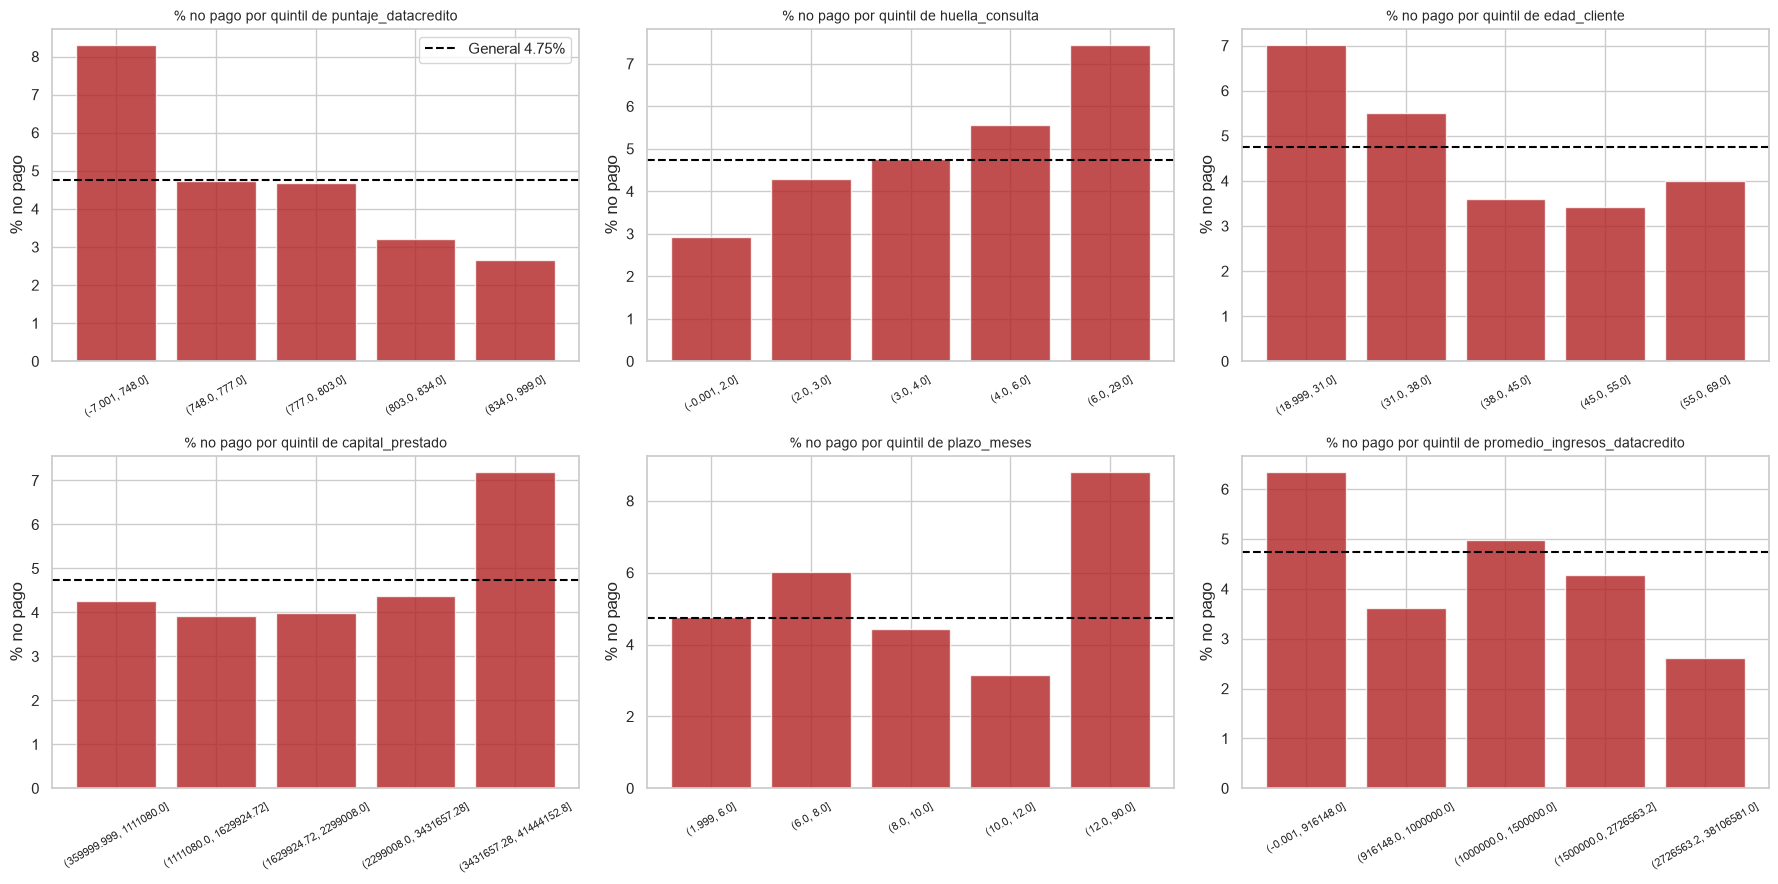

In [35]:
# Tasa de no pago por quintiles de las variables numéricas más relevantes
variables_quintiles = ["puntaje_datacredito", "huella_consulta", "edad_cliente",
                       "capital_prestado", "plazo_meses", "promedio_ingresos_datacredito"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, variables_quintiles):
    grupos = pd.qcut(df[col].astype(float), 5, duplicates="drop")
    tabla = tasa_no_pago(df.assign(grupo=grupos).dropna(subset=["grupo"]), "grupo")
    ax.bar(tabla.index.astype(str), tabla["tasa_no_pago_pct"], color="firebrick", alpha=0.8)
    ax.axhline(TASA_GENERAL, color="black", linestyle="--", label=f"General {TASA_GENERAL:.2f}%")
    ax.set_title(f"% no pago por quintil de {col}", fontsize=10)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.set_ylabel("% no pago")
axes.flat[0].legend()
plt.tight_layout()
plt.show()

Separa a los clientes en dos grupos, con y sin saldo en mora, y calcula la tasa de no pago de cada grupo.

In [36]:
# Clientes con y sin saldo en mora
tasa_no_pago(df.assign(con_saldo_en_mora=df["saldo_mora"].fillna(0) > 0), "con_saldo_en_mora")

,creditos,tasa_no_pago_pct
con_saldo_en_mora,,
False,10708,4.59
True,55,36.36


**Interpretación del análisis bivariable numérico:**

La prueba de Mann-Whitney (no paramétrica, adecuada porque las variables no son normales) compara las distribuciones de quienes pagan y quienes no:

- saldo_mora es la variable numérica más fuerte. Solo 55 clientes tienen saldo en mora, pero su tasa de no pago es del 36,4 %, frente al 4,6 % de los que no tienen mora: casi 8 veces más.

- puntaje_datacredito: a mayor score, menor riesgo. El quintil más bajo (≤ 748) tiene un 8,3 % de no pago y el más alto (> 834) solo un 2,7 %. La relación es clara y monótona.

- huella_consulta: a más consultas recientes al buró, mayor riesgo. Va del 2,9 % (0 a 2 consultas) al 7,5 % (más de 6). Muchas consultas indican que el cliente está buscando crédito en varias entidades, una señal de necesidad de liquidez.

- edad_cliente: los más jóvenes (≤ 31 años) tienen la mayor tasa de no pago (7,0 %) y el grupo de 38 a 55 años, la menor (~3,5 %).

- capital_prestado: los créditos más grandes (quintil superior, > 3,4 millones) tienen un 7,2 % de no pago, frente a ~4 % en el resto.

- plazo_meses: los plazos largos (> 12 meses) tienen el mayor riesgo (8,8 %). La relación no es lineal: 10 a 12 meses es el rango de menor riesgo.

- promedio_ingresos_datacredito: quienes no pagan tienen ingresos menores en el buró (mediana de ~1,05 millones frente a ~1,21 millones). El quintil de ingresos más bajo tiene un 6,3 % de no pago y el más alto, un 2,6 %.

- Sin diferencia significativa (p > 0,05): salario_cliente, cuota_pactada, cant_creditosvigentes, saldo_total, saldo_principal, plazo_meses (en la mediana) y creditos_sectorReal. Por sí solas aportan poco, pero pueden ser útiles combinadas, por ejemplo en ratios.

### 8.2 Variables categóricas frente a Pago_atiempo

Aplica la prueba chi-cuadrado a cada variable categórica. Primero arma una tabla de contingencia (categorías × Pago_atiempo) y luego la prueba dice si la categoría y el pago están asociados. Si p < 0,05, la asociación es significativa.

In [37]:
filas = []
for col in variables_categoricas:
    tabla = pd.crosstab(con_sin_dato(df[col]), df["Pago_atiempo"])
    chi2, p_valor, _, _ = stats.chi2_contingency(tabla)
    filas.append({"variable": col, "chi2": chi2, "p_valor": p_valor,
                  "asociacion_significativa": "Sí" if p_valor < 0.05 else "No"})
pd.DataFrame(filas).set_index("variable")

,chi2,p_valor,asociacion_significativa
variable,,,
tipo_credito,68.86,0.00,Sí
tipo_laboral,8.00,0.00,Sí
tendencia_ingresos,19.92,0.00,Sí


 Calcula la tasa de no pago de cada categoría de las 3 variables categóricas y la dibuja en gráficos de barras, con el número de créditos de cada categoría (n) escrito encima y la tasa general como línea de referencia.

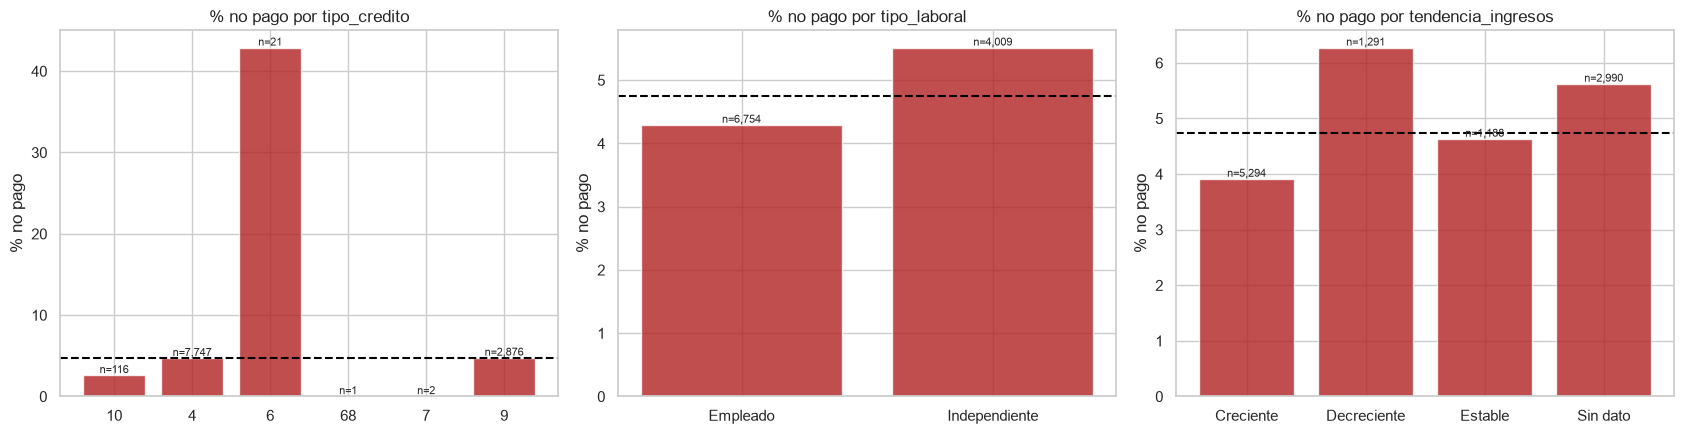

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, variables_categoricas):
    datos = df.assign(cat=con_sin_dato(df[col]))
    tabla = tasa_no_pago(datos, "cat")
    barras = ax.bar(tabla.index, tabla["tasa_no_pago_pct"], color="firebrick", alpha=0.8)
    for barra, n in zip(barras, tabla["creditos"]):
        ax.annotate(f"n={n:,}", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                    ha="center", va="bottom", fontsize=8)
    ax.axhline(TASA_GENERAL, color="black", linestyle="--")
    ax.set_title(f"% no pago por {col}")
    ax.set_ylabel("% no pago")
plt.tight_layout()
plt.show()

Para cada variable categórica arma una tabla cruzada en porcentajes por fila: cada fila suma 100 %, así que se lee directamente qué % de cada categoría pagó y qué % no.

In [39]:
for col in variables_categoricas:
    print(f"===== {col} (% por fila) =====")
    display((pd.crosstab(con_sin_dato(df[col]), df["Pago_atiempo"],
                         normalize="index") * 100).round(2))

===== tipo_credito (% por fila) =====


Pago_atiempo,0,1
tipo_credito,,
10,2.59,97.41
4,4.69,95.31
6,42.86,57.14
68,0.00,100.00
7,0.00,100.00
9,4.73,95.27


===== tipo_laboral (% por fila) =====


Pago_atiempo,0,1
tipo_laboral,,
Empleado,4.29,95.71
Independiente,5.51,94.49


===== tendencia_ingresos (% por fila) =====


Pago_atiempo,0,1
tendencia_ingresos,,
Creciente,3.91,96.09
Decreciente,6.27,93.73
Estable,4.63,95.37
Sin dato,5.62,94.38


**Interpretación del análisis bivariable categórico:**

Las tres variables categóricas tienen una asociación estadísticamente significativa con el pago (prueba chi-cuadrado, p < 0,05):

- tipo_credito: el tipo 6 tiene una tasa de no pago del 42,9 %, nueve veces la general, aunque con solo 21 créditos. El tipo 10 es el de menor riesgo (2,6 %). Los tipos 4 y 9 están cerca del promedio. Al agrupar las categorías raras en "Otros" se pierde esta señal del tipo 6, así que vale la pena evaluar si se deja como categoría aparte.

- tipo_laboral: los independientes tienen más riesgo (5,5 %) que los empleados (4,3 %), lo cual es coherente con ingresos menos estables.

- tendencia_ingresos: los clientes con ingresos decrecientes tienen la mayor tasa de no pago (6,3 %) y los de ingresos crecientes, la menor (3,9 %). Los clientes sin dato (5,6 %) también tienen un riesgo mayor que el promedio, lo que confirma que conviene conservar la ausencia de información como señal.

### 8.3 Variable temporal frente a Pago_atiempo

Agrupa los créditos por mes de desembolso, calcula la tasa de no pago de cada mes, deja solo los meses con al menos 30 créditos (con menos, el porcentaje es muy inestable) y dibuja la evolución en un gráfico de línea.

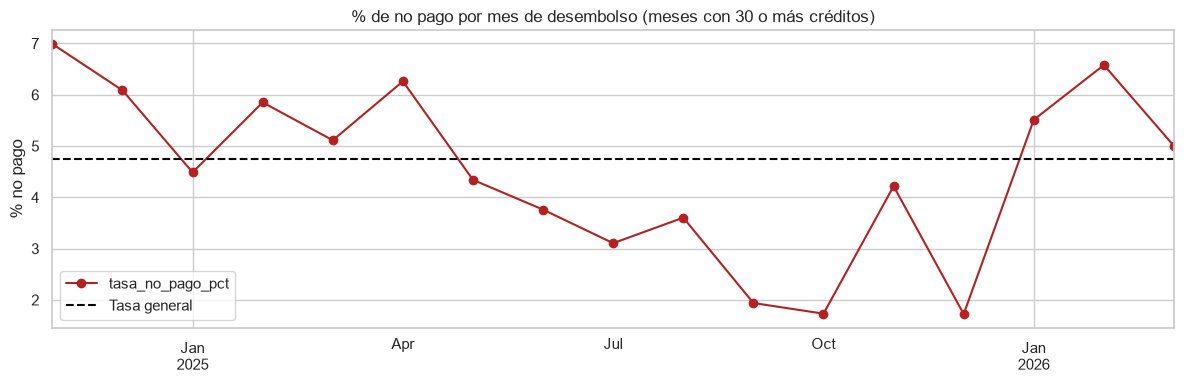

In [40]:
tasa_mes = (df.set_index("fecha_prestamo").resample("MS")["Pago_atiempo"]
              .agg(["count", lambda s: (1 - s.mean()) * 100]))
tasa_mes.columns = ["creditos", "tasa_no_pago_pct"]
tasa_mes = tasa_mes[tasa_mes["creditos"] >= 30]  # se omiten meses con muy pocos créditos

fig, ax = plt.subplots(figsize=(12, 4))
tasa_mes["tasa_no_pago_pct"].plot(marker="o", color="firebrick", ax=ax)
ax.axhline(TASA_GENERAL, color="black", linestyle="--", label="Tasa general")
ax.set_title("% de no pago por mes de desembolso (meses con 30 o más créditos)")
ax.set_ylabel("% no pago")
ax.set_xlabel("")
ax.legend()
plt.tight_layout()
plt.show()

Extrae el día de la semana de cada fecha de desembolso, lo traduce a su nombre y calcula la tasa de no pago de cada día, ordenando de lunes a domingo.

In [41]:
dias = {0: "Lunes", 1: "Martes", 2: "Miércoles", 3: "Jueves", 4: "Viernes", 5: "Sábado", 6: "Domingo"}
tasa_no_pago(df.assign(dia_semana=df["fecha_prestamo"].dt.dayofweek.map(dias)), "dia_semana").reindex(dias.values())

C:\Users\juang\AppData\Local\Temp\ipykernel_6664\3115717985.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  tasa_no_pago(df.assign(dia_semana=df["fecha_prestamo"].dt.dayofweek.map(dias)), "dia_semana").reindex(dias.values())


,creditos,tasa_no_pago_pct
dia_semana,,
Lunes,1307,4.97
Martes,1412,3.33
Miércoles,1254,3.51
Jueves,1899,4.79
Viernes,1789,3.91
Sábado,1621,6.23
Domingo,1481,6.28


**Interpretación:**
- La tasa de no pago cambia con el tiempo: arranca alta a finales de 2024 (~7 %), baja de forma sostenida durante 2025 hasta menos del 2 % en septiembre y octubre, y vuelve a subir en 2026 (5 % a 6,6 %). Puede deberse a cambios en las políticas de aprobación, en el perfil de los clientes o en la economía. Los meses de finales de 2025 y de 2026 tienen pocos créditos, así que sus tasas son menos estables. Esta inestabilidad hay que tenerla en cuenta al separar los datos de entrenamiento y prueba, y en el monitoreo de drift.

- Fin de semana: los créditos desembolsados el sábado o el domingo tienen una tasa de no pago de ~6,3 %, frente a 3,3 % a 5 % entre semana. Puede reflejar canales de venta o perfiles de cliente distintos. Es un buen candidato a variable derivada.

## 9. Análisis multivariable

### 9.1 Matriz de correlación

Se usa la correlación de **Spearman** en lugar de la de Pearson, porque las variables no son normales y tienen valores extremos. Spearman trabaja con rangos, así que es robusta frente a esos valores y detecta relaciones monótonas aunque no sean lineales.

 Calcula la correlación de Spearman entre todas las parejas de variables numéricas (incluida la objetivo) y la dibuja como un mapa de calor. Solo se muestra la mitad inferior, porque la superior es un espejo

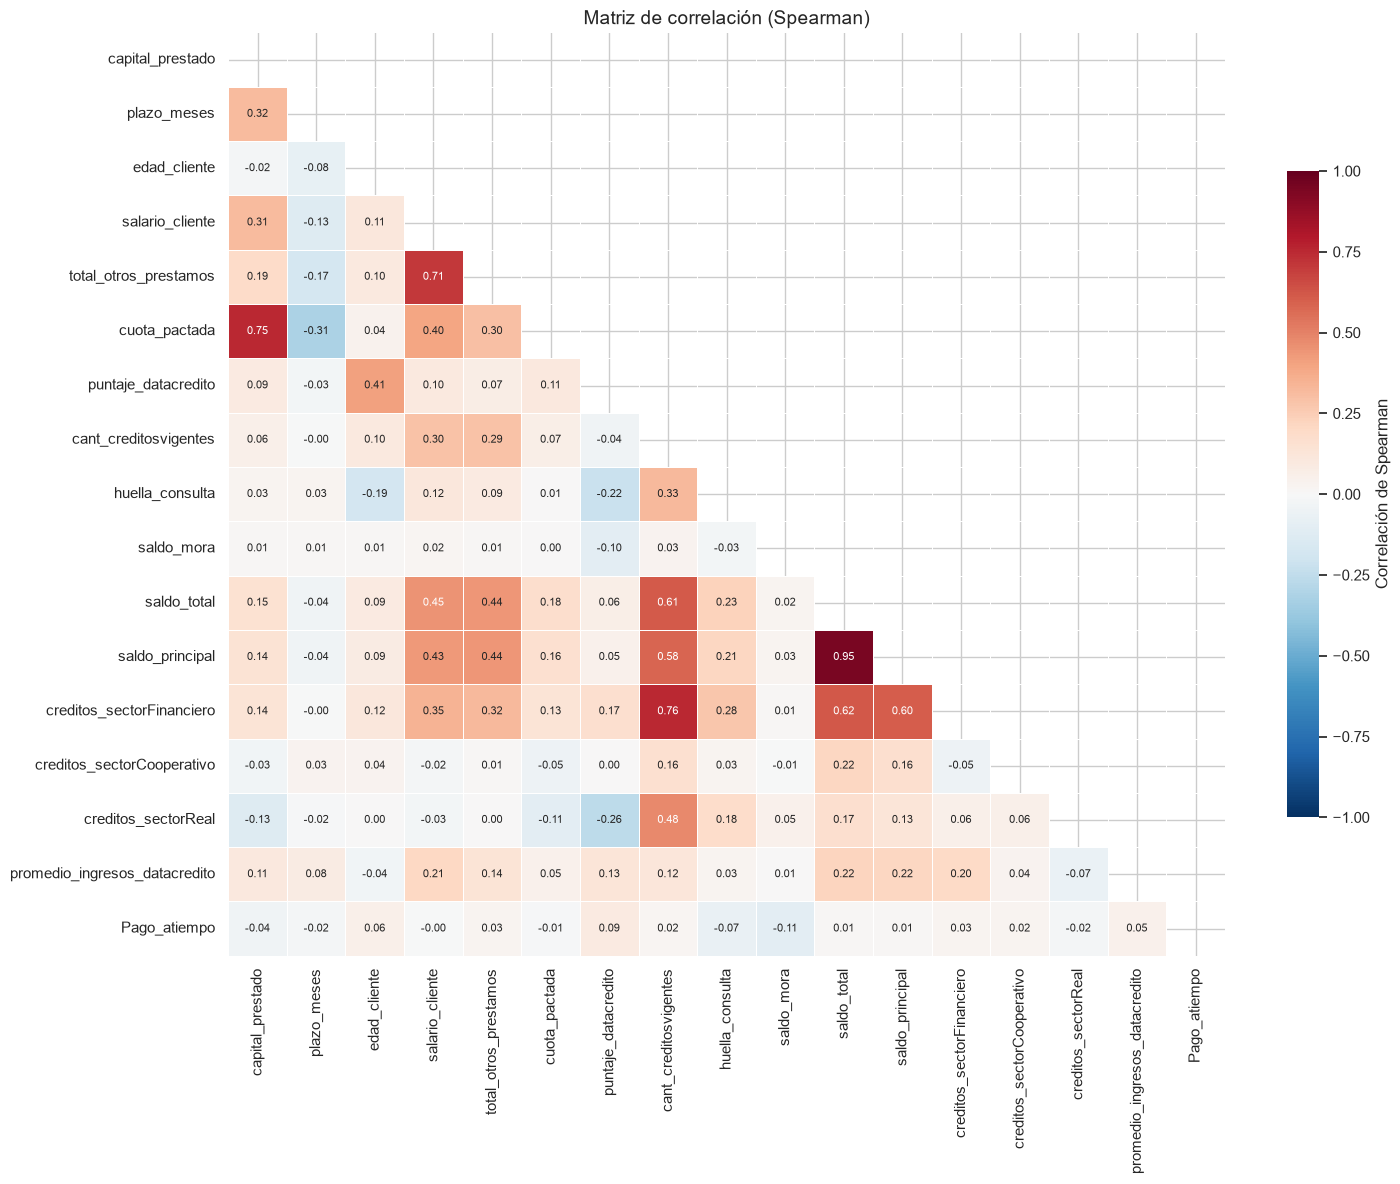

In [42]:
columnas_corr = variables_numericas + ["Pago_atiempo"]
matriz_corr = df[columnas_corr].astype(float).corr(method="spearman")

mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(matriz_corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, linewidths=0.5, annot_kws={"size": 8},
            cbar_kws={"shrink": 0.7, "label": "Correlación de Spearman"}, ax=ax)
ax.set_title("Matriz de correlación (Spearman)", fontsize=14)
plt.tight_layout()
plt.show()

Recorre todas las parejas de variables de la matriz anterior, una sola vez cada una, y guarda las que tienen una correlación fuerte (|r| ≥ 0,7). Las muestra ordenadas de la más fuerte a la más débil.

In [43]:
UMBRAL = 0.7
pares = []
for i, var1 in enumerate(columnas_corr):
    for var2 in columnas_corr[i + 1:]:
        r = matriz_corr.loc[var1, var2]
        if abs(r) >= UMBRAL:
            pares.append({"variable_1": var1, "variable_2": var2, "correlacion": round(r, 3)})
pd.DataFrame(pares).sort_values("correlacion", key=abs, ascending=False)

,variable_1,variable_2,correlacion
3,saldo_total,saldo_principal,0.95
2,cant_creditosvigentes,creditos_sectorFinanciero,0.76
0,capital_prestado,cuota_pactada,0.75
1,salario_cliente,total_otros_prestamos,0.70


 Toma de la matriz la columna de correlaciones con Pago_atiempo, la ordena por fuerza (sin importar el signo) y la dibuja como barras horizontales

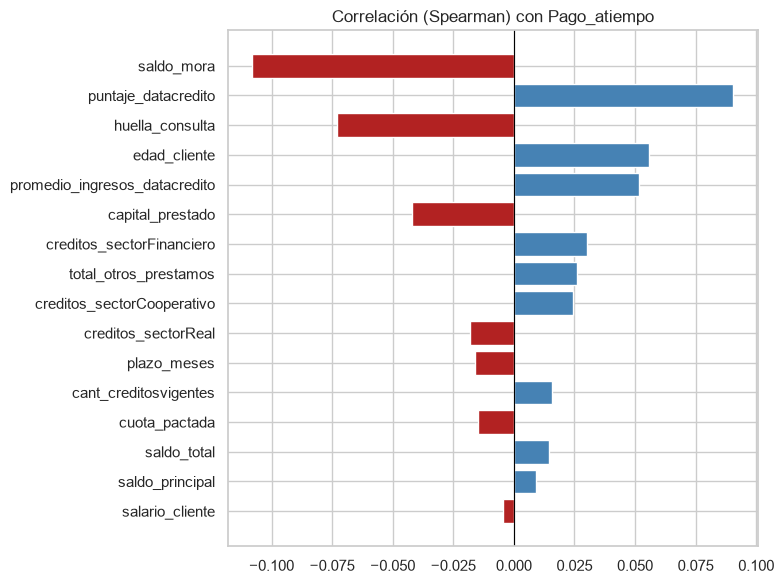

In [44]:
corr_objetivo = matriz_corr["Pago_atiempo"].drop("Pago_atiempo").sort_values(key=abs, ascending=False)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(corr_objetivo.index, corr_objetivo.values,
        color=["firebrick" if v < 0 else "steelblue" for v in corr_objetivo])
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlación (Spearman) con Pago_atiempo")
plt.tight_layout()
plt.show()

**Interpretación de la matriz de correlación:**

Variables muy correlacionadas entre sí (redundancia):
- saldo_total y saldo_principal (0,95): prácticamente miden lo mismo, así que conviene quedarse con una sola.

- cant_creditosvigentes y creditos_sectorFinanciero (0,76): la mayoría de los créditos vigentes son del sector financiero.

- capital_prestado y cuota_pactada (0,75): es lógico, porque a mayor monto, mayor cuota.

- salario_cliente y total_otros_prestamos (0,70): quien gana más, tiene más deudas. En lugar de eliminar una, se pueden combinar en un ratio de endeudamiento.

La alta correlación entre predictoras (multicolinealidad) afecta sobre todo a la regresión logística. Los modelos de árboles son más tolerantes a ella.


Relación con la variable objetivo: todas las correlaciones individuales son bajas (|r| < 0,12), lo cual es normal en riesgo crediticio. Ninguna variable predice el pago por sí sola; el modelo tendrá que combinar varias señales. Las más relacionadas son saldo_mora (-0,11), puntaje_datacredito (+0,09) y huella_consulta (-0,07).

### 9.2 Pairplot con `hue` en la variable objetivo

 Prepara 5 variables clave (aplica logaritmo al capital y a la cuota para reducir el efecto de los valores extremos) y dibuja un pairplot: una cuadrícula que muestra la relación entre cada pareja de variables, coloreada según Pago_atiempo.

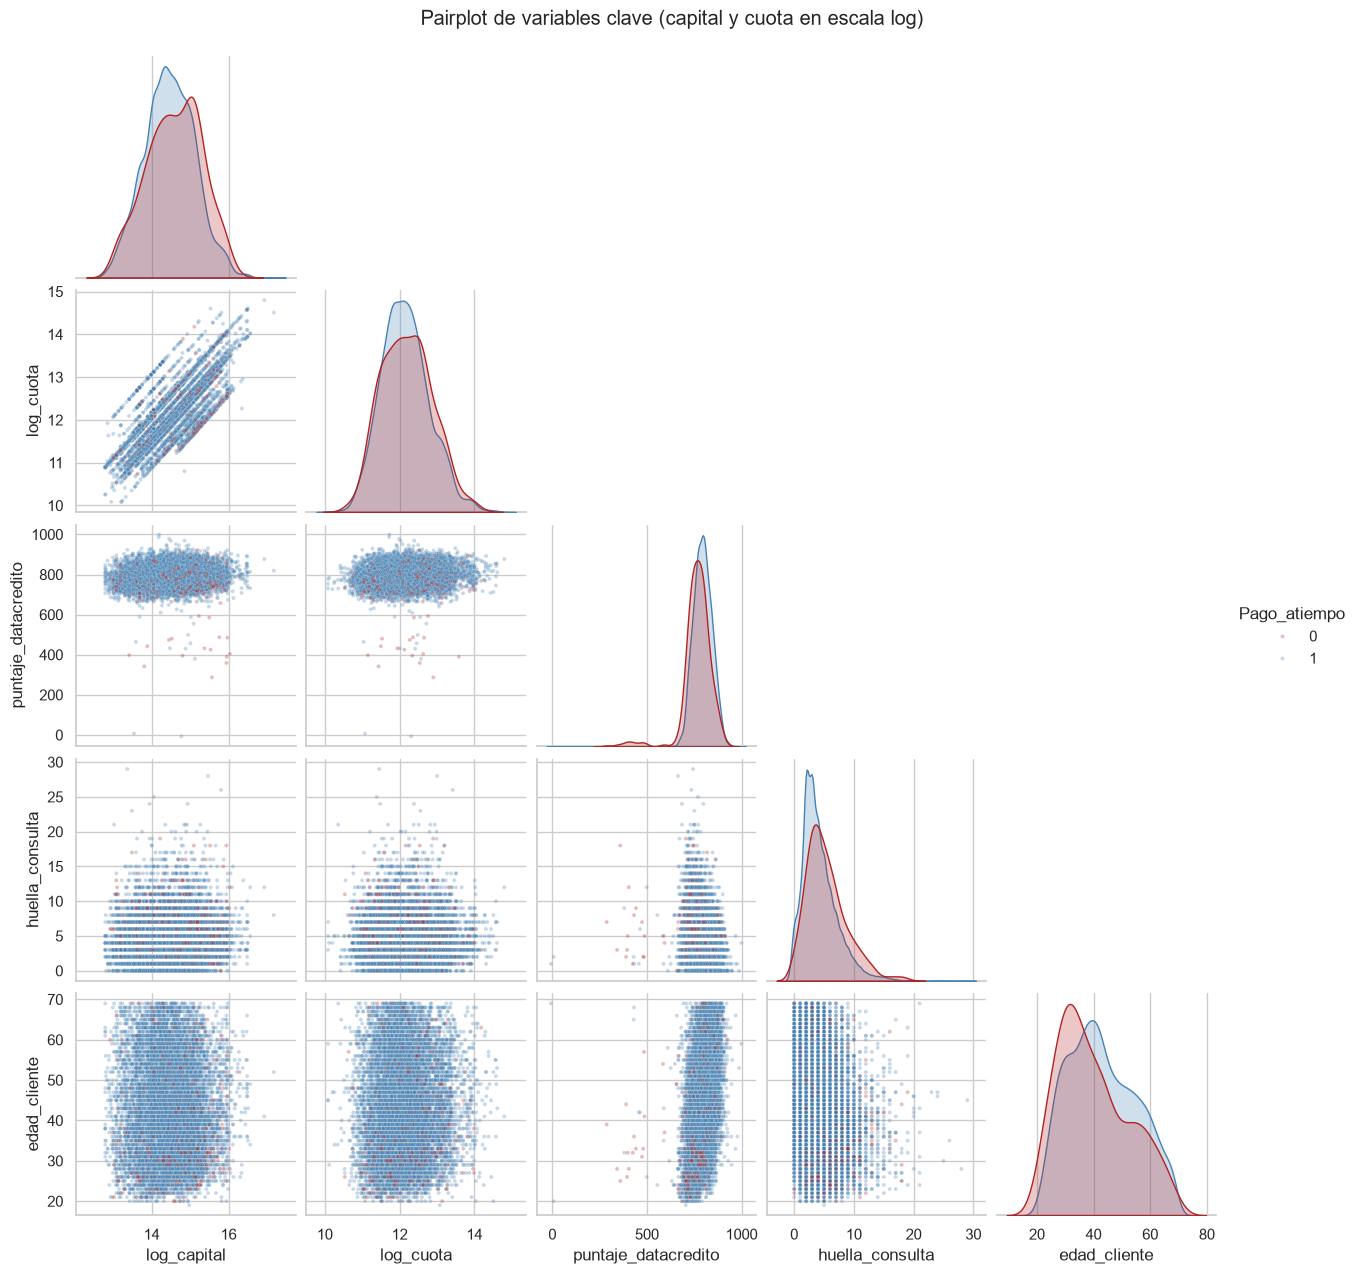

In [45]:
variables_pairplot = ["capital_prestado", "cuota_pactada", "puntaje_datacredito", "huella_consulta", "edad_cliente"]
datos_pair = df[variables_pairplot + ["Pago_atiempo"]].dropna().astype(float)
datos_pair["capital_prestado"] = np.log1p(datos_pair["capital_prestado"])
datos_pair["cuota_pactada"] = np.log1p(datos_pair["cuota_pactada"])
datos_pair = datos_pair.rename(columns={"capital_prestado": "log_capital", "cuota_pactada": "log_cuota"})
datos_pair["Pago_atiempo"] = datos_pair["Pago_atiempo"].astype(int)

g = sns.pairplot(datos_pair, hue="Pago_atiempo", palette=COLORES_OBJETIVO, corner=True,
                 plot_kws={"alpha": 0.3, "s": 8}, diag_kws={"common_norm": False})
g.figure.suptitle("Pairplot de variables clave (capital y cuota en escala log)", y=1.02)
plt.show()

Interpretación: en las diagonales (distribuciones por clase), las curvas de quienes no pagan (rojo) están desplazadas hacia puntajes de Datacrédito más bajos, más consultas y menor edad (el pico rojo de edad está cerca de los 32 años). Los pocos clientes con puntaje de Datacrédito por debajo de 600 son casi todos rojos, una señal de riesgo muy clara aunque afecta a pocos casos. En los gráficos de dispersión, las dos clases se superponen mucho: no hay una frontera simple que las separe. Por eso se necesitan modelos que combinen varias variables, y modelos no lineales como los árboles pueden tener ventaja. La relación entre log_capital y log_cuota se ve como una banda diagonal, que confirma su correlación positiva.

### 9.3 Gráficos de dispersión

Dibuja dos gráficos de dispersión lado a lado: capital vs. cuota, coloreado por tipo de crédito, y salario vs. otros préstamos, coloreado por Pago_atiempo. Ambos usan escala logarítmica para que los valores grandes no aplasten a los pequeños.

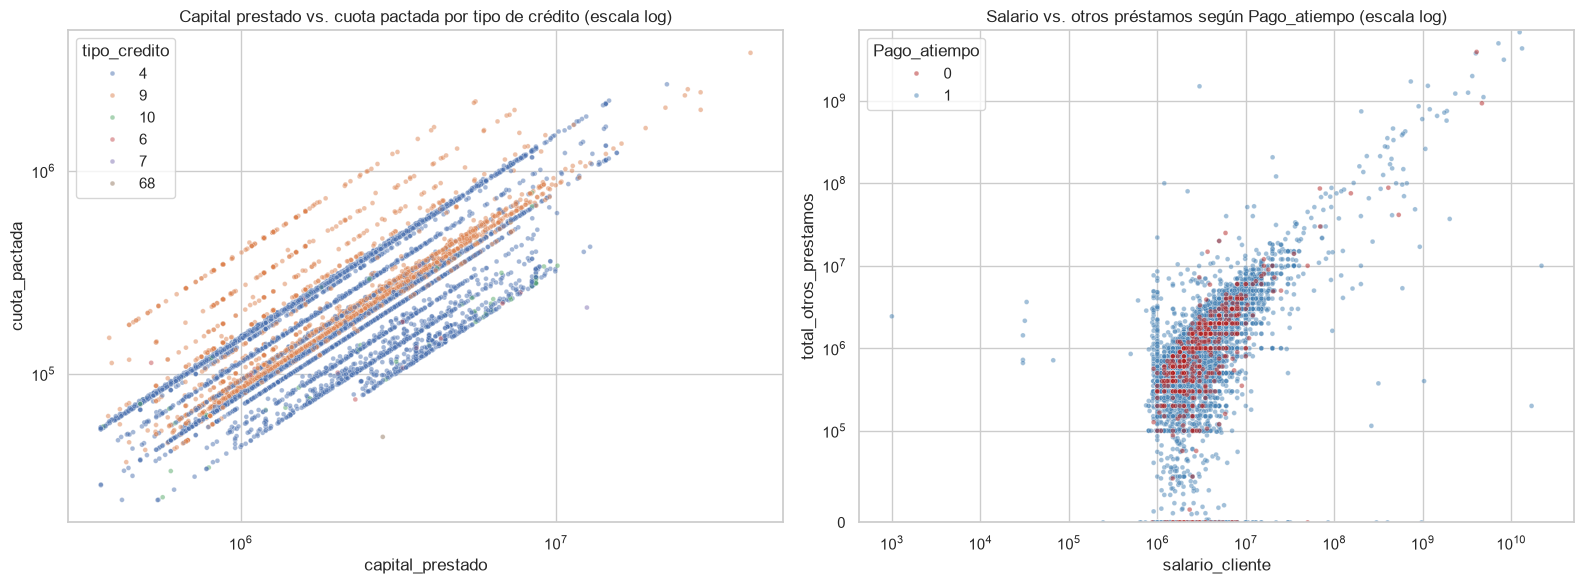

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=df.assign(tipo_credito=df["tipo_credito"].astype(str)),
                x="capital_prestado", y="cuota_pactada", hue="tipo_credito",
                alpha=0.5, s=12, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Capital prestado vs. cuota pactada por tipo de crédito (escala log)")

sns.scatterplot(data=df.sort_values("Pago_atiempo", ascending=False),
                x="salario_cliente", y="total_otros_prestamos", hue="Pago_atiempo",
                palette=COLORES_OBJETIVO, alpha=0.5, s=12, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_yscale("symlog", linthresh=1e5)
axes[1].set_ylim(bottom=0)
axes[1].set_title("Salario vs. otros préstamos según Pago_atiempo (escala log)")

plt.tight_layout()
plt.show()

**Interpretación:**
- Capital vs. cuota: se ven varias "líneas" paralelas, una por cada plazo: para un mismo capital, a mayor plazo, menor cuota. El tipo 9 (naranja) aparece en las líneas superiores: para el mismo capital tiene cuotas más altas que el tipo 4, lo que sugiere tasas de interés mayores o plazos más cortos. Es decir, los tipos de crédito tienen condiciones financieras distintas.

- Salario vs. otros préstamos: los dos crecen juntos. Los que no pagan (rojo) aparecen en todo el rango, sin concentrarse en una zona, lo que confirma que el monto de las deudas por sí solo no explica el no pago. También se ven valores extremos (salarios > 100 millones) que son poco creíbles.


### 9.4 Tablas cruzadas entre varias variables

Calcula la tasa de no pago para cada combinación de tipo laboral y tendencia de ingresos, y la dibuja como un mapa de calor con el valor escrito en cada celda.

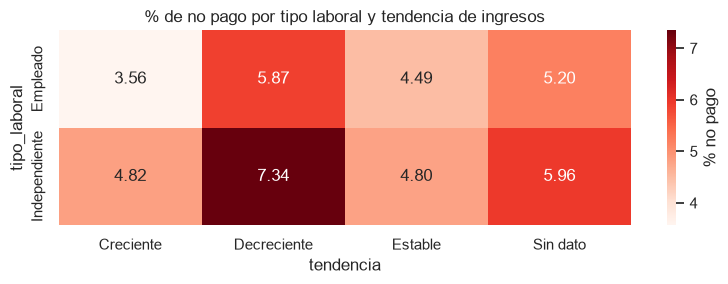

In [47]:
tabla_lab_tend = pd.pivot_table(
    df.assign(tendencia=con_sin_dato(df["tendencia_ingresos"])),
    index="tipo_laboral", columns="tendencia", values="Pago_atiempo",
    aggfunc=lambda s: (1 - s.mean()) * 100, observed=True)

fig, ax = plt.subplots(figsize=(8, 3))
sns.heatmap(tabla_lab_tend, annot=True, fmt=".2f", cmap="Reds", cbar_kws={"label": "% no pago"}, ax=ax)
ax.set_title("% de no pago por tipo laboral y tendencia de ingresos")
plt.tight_layout()
plt.show()

Tabla pivote que cruza tipo de crédito (filas) con tipo laboral (columnas) y muestra, para cada combinación, cuántos créditos hay y su % de no pago.

In [48]:
pd.pivot_table(df, index="tipo_credito", columns="tipo_laboral", values="Pago_atiempo",
               aggfunc=["count", lambda s: round((1 - s.mean()) * 100, 2)], observed=True)

count               <lambda>              
tipo_laboral Empleado Independiente Empleado Independiente
tipo_credito                                              
4            5,052.00      2,695.00     4.14          5.71
6               21.00           NaN    42.86           NaN
7                1.00          1.00     0.00          0.00
9            1,604.00      1,272.00     4.36          5.19
10              75.00         41.00     2.67          2.44
68               1.00           NaN     0.00           NaN

Dibuja el puntaje de Datacrédito como cajas, agrupadas por tendencia de ingresos y separadas por Pago_atiempo. Así se ven tres variables al mismo tiempo.

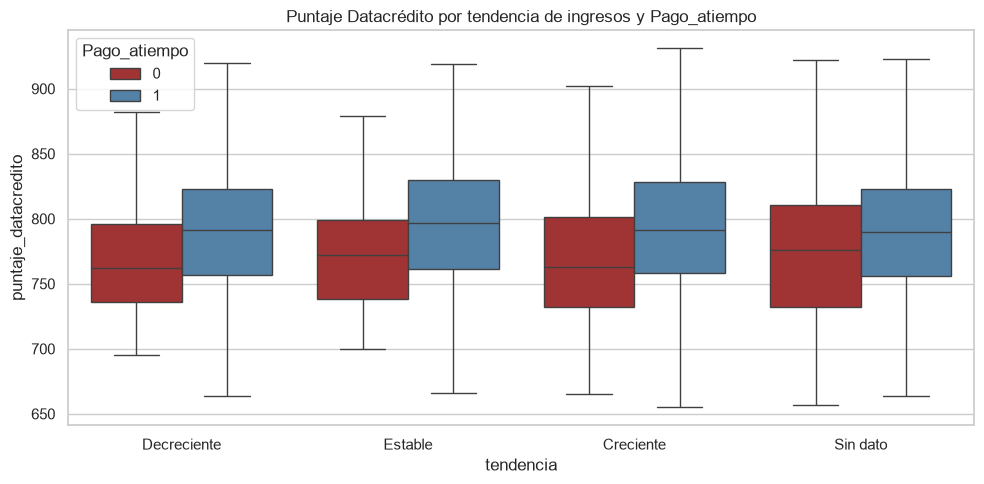

In [49]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df.assign(tendencia=con_sin_dato(df["tendencia_ingresos"])),
            x="tendencia", y="puntaje_datacredito", hue="Pago_atiempo", palette=COLORES_OBJETIVO,
            order=["Decreciente", "Estable", "Creciente", "Sin dato"], showfliers=False, ax=ax)
ax.set_title("Puntaje Datacrédito por tendencia de ingresos y Pago_atiempo")
plt.tight_layout()
plt.show()

**Interpretación:**
- Tipo laboral × tendencia de ingresos: los efectos se suman. El grupo de mayor riesgo es independiente con ingresos decrecientes (~7,3 % de no pago) y el de menor riesgo, empleado con ingresos crecientes (~3,6 %). Este tipo de interacción la capturan mejor los modelos de árboles.

- Tipo de crédito × tipo laboral: en los tipos 4 y 9, los independientes siempre tienen mayor riesgo que los empleados.

- Puntaje × tendencia: en todas las categorías de tendencia, quienes no pagan tienen un puntaje de Datacrédito menor. Es decir, el puntaje aporta información adicional a la tendencia de ingresos.

## 10. Reglas de validación de datos

A partir del análisis, se definen reglas para validar los datos que lleguen al modelo, tanto en el entrenamiento como en producción. Se aplican sobre los datos originales para medir cuántos registros las incumplen. Estas reglas se usarán en ft_engineering.py, en la API (model_deploy.py) y en el monitoreo.

- Error: el dato es imposible y se debe corregir o convertir a nulo.
- Advertencia: el dato es poco común y conviene revisarlo.

Define la función validar_datos, que revisa 19 reglas de validación sobre una tabla. Cada regla tiene una descripción, una severidad (Error si el dato es imposible, Advertencia si es poco común) y una condición que marca los registros que la incumplen. Las reglas cubren rangos válidos (edad, plazo, puntaje), valores positivos, coherencia entre columnas (cuota ≤ capital, saldo principal ≤ saldo total), categorías permitidas, fechas, duplicados y valores sospechosos. La función devuelve cuántos registros incumplen cada regla y qué % representan. Se aplica sobre df_original, los datos antes de la limpieza, para medir los problemas reales. Esta misma función se podrá reutilizar en el pipeline, en la API y en el monitoreo.

In [50]:
def validar_datos(data: pd.DataFrame) -> pd.DataFrame:
    """Evalúa las reglas de validación y devuelve cuántos registros incumple cada una."""
    num = lambda c: pd.to_numeric(data[c], errors="coerce")
    reglas = [
        ("edad_cliente entre 18 y 100 años", "Error", ~num("edad_cliente").between(18, 100)),
        ("salario_cliente mayor que 0", "Error", num("salario_cliente") <= 0),
        ("capital_prestado mayor que 0", "Error", num("capital_prestado") <= 0),
        ("cuota_pactada mayor que 0", "Error", num("cuota_pactada") <= 0),
        ("cuota_pactada <= capital_prestado", "Error", num("cuota_pactada") > num("capital_prestado")),
        ("plazo_meses entre 1 y 60", "Error", ~num("plazo_meses").between(1, 60)),
        ("montos y conteos no negativos", "Error",
         (data[["total_otros_prestamos", "saldo_mora", "saldo_total", "saldo_principal",
                "cant_creditosvigentes", "huella_consulta", "creditos_sectorFinanciero",
                "creditos_sectorCooperativo", "creditos_sectorReal"]] < 0).any(axis=1)),
        ("saldo_principal <= saldo_total", "Error", num("saldo_principal") > num("saldo_total")),
        ("puntaje_datacredito en 0 (sin historial) o entre 150 y 950", "Error",
         num("puntaje_datacredito").notna() & (num("puntaje_datacredito") != 0)
         & ~num("puntaje_datacredito").between(150, 950)),
        ("tendencia_ingresos en {Creciente, Decreciente, Estable} o nulo", "Error",
         data["tendencia_ingresos"].notna()
         & ~data["tendencia_ingresos"].astype(str).isin(["Creciente", "Decreciente", "Estable"])),
        ("tipo_laboral en {Empleado, Independiente}", "Error",
         ~data["tipo_laboral"].astype(str).isin(["Empleado", "Independiente"])),
        ("Pago_atiempo en {0, 1}", "Error", ~num("Pago_atiempo").isin([0, 1])),
        ("fecha_prestamo no futura y desde 2024", "Error",
         (data["fecha_prestamo"] > pd.Timestamp.today()) | (data["fecha_prestamo"] < "2024-01-01")),
        ("sin filas duplicadas", "Error", data.duplicated()),
        ("tipo_credito en los códigos conocidos {4, 6, 9, 10}", "Advertencia",
         ~num("tipo_credito").isin([4, 6, 9, 10])),
        ("salario_cliente <= 100 millones", "Advertencia", num("salario_cliente") > 100_000_000),
        ("total_otros_prestamos <= 100 millones", "Advertencia", num("total_otros_prestamos") > 100_000_000),
        ("cuota_pactada <= salario_cliente", "Advertencia", num("cuota_pactada") > num("salario_cliente")),
        ("cant_creditosvigentes <= 30", "Advertencia", num("cant_creditosvigentes") > 30),
    ]
    return pd.DataFrame([
        {"regla": nombre, "severidad": severidad, "registros_incumplen": int(mascara.sum()),
         "%_incumplen": round(mascara.mean() * 100, 2)}
        for nombre, severidad, mascara in reglas
    ])


reporte_validacion = validar_datos(df_original)
reporte_validacion

,regla,severidad,registros_incumplen,%_incumplen
0,edad_cliente entre 18 y 100 años,Error,150,1.39
1,salario_cliente mayor que 0,Error,24,0.22
2,capital_prestado mayor que 0,Error,0,0.00
3,cuota_pactada mayor que 0,Error,0,0.00
4,cuota_pactada <= capital_prestado,Error,0,0.00
5,plazo_meses entre 1 y 60,Error,1,0.01
6,montos y conteos no negativos,Error,0,0.00
7,saldo_principal <= saldo_total,Error,0,0.00
8,puntaje_datacredito en 0 (sin historial) o ent...,Error,8,0.07
9,"tendencia_ingresos en {Creciente, Decreciente,...",Error,58,0.54


**Interpretación de las reglas de validación:**
- **Edad:** 150 registros con 121 a 123 años, convertidos a nulo en la sección 4.
- **Salario:** 24 salarios en 0 (convertidos a nulo), 74 por encima de 100 millones y 44 clientes con otros préstamos de más de 100 millones. Son valores sospechosos que se deben **limitar** (*winsorizar*) antes del modelado.
- **`puntaje_datacredito`:** 3 valores fuera del rango válido de Datacrédito (-7, 7 y 999).
- **`tendencia_ingresos`:** 58 valores inválidos, ya convertidos a nulo.
- **`plazo_meses`:** 1 crédito a 90 meses, muy por encima del resto.
- **`tipo_credito`:** los códigos 7 y 68 (3 registros) son poco frecuentes y deberían validarse con el área de negocio.
- **Cuota mayor que el salario:** 35 registros, lo cual es financieramente poco viable.
- Las reglas de consistencia (cuota ≤ capital, saldo principal ≤ saldo total, no negativos, sin duplicados, fechas válidas) se cumplen en el 100 % de los registros.

## 11. Transformaciones propuestas

Estas transformaciones se implementarán en el pipeline de `ft_engineering.py`:

| Variable(s) | Problema identificado | Transformación |
|---|---|---|
| `puntaje`, `saldo_mora_codeudor` | Fuga de información / casi constante | **Eliminar** |
| `saldo_principal` | Redundante con `saldo_total` (0,95) | **Eliminar** una de las dos |
| `edad_cliente` (121 a 123), `salario_cliente` (0), `tendencia_ingresos` (números) | Valores imposibles | Convertir a **NaN** y luego imputar |
| Variables numéricas con nulos | Faltantes (hasta 27 %) | Imputar con la **mediana** (robusta a atípicos) con `SimpleImputer` |
| `tendencia_ingresos`, `tipo_laboral` | Faltantes en categóricas | Imputar con la **moda** o una categoría **"Sin dato"** |
| `salario_cliente`, `total_otros_prestamos`, `capital_prestado`, `cuota_pactada`, saldos, `promedio_ingresos_datacredito` | Asimetría fuerte y valores extremos | **Winsorizar** (limitar al percentil 1 y 99) y aplicar **`log1p`** |
| `tipo_credito` | Categorías raras (6, 7, 10, 68) | Agrupar las de menos de ~1 % en **"Otros"**, evaluando si conviene dejar el tipo 6 aparte |
| `tipo_credito`, `tipo_laboral` | Nominales | **OneHotEncoder** |
| `tendencia_ingresos` | Ordinal | **OrdinalEncoder** (Decreciente = 0, Estable = 1, Creciente = 2) |
| Todas las numéricas | Escalas muy diferentes | **StandardScaler** (necesario para regresión logística, no para árboles) |
| `fecha_prestamo` | Fecha en bruto | Extraer atributos (mes, día de la semana, fin de semana) y eliminar la fecha |
| `Pago_atiempo` | Clases desbalanceadas (95 / 5) | `stratify` en la partición y `class_weight="balanced"` o SMOTE |

## 12. Atributos derivados

Se crean nuevas variables a partir de las existentes y se evalúa si separan mejor a quienes pagan de quienes no.

aca se crea las variables derivadas sobre una copia de los datos.Primero, 4 indicadores 0/1: si el cliente tiene saldo en mora, si no tiene información de ingresos en Datacrédito, si no tiene historial (puntaje 0) y si el crédito se desembolsó en fin de semana. Luego, 4 ratios de capacidad de pago: cuota / salario, otros préstamos / salario, capital / salario y cuota / ingreso reportado al buró. Por último, el mes y el día de la semana del desembolso y el total de créditos en los tres sectores. Al final muestra las estadísticas de los ratios.

In [51]:
df_deriv = df.copy()
salario = df_deriv["salario_cliente"].astype(float)

# Indicadores (0/1)
df_deriv["tiene_mora"] = (df_deriv["saldo_mora"].fillna(0) > 0).astype(int)
df_deriv["sin_info_datacredito"] = df_deriv["promedio_ingresos_datacredito"].isna().astype(int)
df_deriv["sin_historial_datacredito"] = (df_deriv["puntaje_datacredito"] == 0).astype(int)
df_deriv["fin_de_semana"] = (df_deriv["fecha_prestamo"].dt.dayofweek >= 5).astype(int)

# Ratios de capacidad de pago
df_deriv["cuota_salario"] = df_deriv["cuota_pactada"] / salario
df_deriv["endeudamiento"] = df_deriv["total_otros_prestamos"] / salario
df_deriv["capital_salario"] = df_deriv["capital_prestado"] / salario
df_deriv["cuota_ingreso_datacredito"] = (df_deriv["cuota_pactada"]
                                         / df_deriv["promedio_ingresos_datacredito"].replace(0, np.nan))

# Atributos de fecha
df_deriv["mes_prestamo"] = df_deriv["fecha_prestamo"].dt.month
df_deriv["dia_semana"] = df_deriv["fecha_prestamo"].dt.dayofweek

# Otros
df_deriv["total_creditos_sectores"] = (df_deriv["creditos_sectorFinanciero"]
                                       + df_deriv["creditos_sectorCooperativo"]
                                       + df_deriv["creditos_sectorReal"])

nuevas_binarias = ["tiene_mora", "sin_info_datacredito", "sin_historial_datacredito", "fin_de_semana"]
nuevas_ratios = ["cuota_salario", "endeudamiento", "capital_salario", "cuota_ingreso_datacredito"]
df_deriv[nuevas_ratios].describe().T

C:\Users\juang\AppData\Local\Temp\ipykernel_6664\2236417810.py:8: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_deriv["fin_de_semana"] = (df_deriv["fecha_prestamo"].dt.dayofweek >= 5).astype(int)
C:\Users\juang\AppData\Local\Temp\ipykernel_6664\2236417810.py:19: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_deriv["dia_semana"] = df_deriv["fecha_prestamo"].dt.dayofweek


,count,mean,std,min,25%,50%,75%,max
cuota_salario,"10,739.00",0.09,1.24,0.00,0.04,0.06,0.10,125.80
endeudamiento,"10,739.00",0.69,24.08,0.00,0.21,0.33,0.47,"2,439.00"
capital_salario,"10,739.00",0.92,8.34,0.00,0.37,0.63,1.02,840.00
cuota_ingreso_datacredito,"7,826.00",0.35,2.07,0.00,0.07,0.13,0.24,125.80


se calcula la tasa de no pago para el valor 0 y el valor 1 de cada indicador nuevo y une estos resultados en una tabla 

In [52]:
# Tasa de no pago según los indicadores binarios
tablas = []
for col in nuevas_binarias:
    t = tasa_no_pago(df_deriv, col)
    t.index = [f"{col} = {i}" for i in t.index]
    tablas.append(t)
pd.concat(tablas)

,creditos,tasa_no_pago_pct
tiene_mora = 0,10708,4.59
tiene_mora = 1,55,36.36
sin_info_datacredito = 0,7833,4.38
sin_info_datacredito = 1,2930,5.73
sin_historial_datacredito = 0,10618,4.72
sin_historial_datacredito = 1,145,6.90
fin_de_semana = 0,7661,4.14
fin_de_semana = 1,3102,6.25


Divide cada uno de los 4 ratios nuevos en quintiles (Q1 = valores más bajos, Q5 = más altos) y dibuja la tasa de no pago de cada quintil.

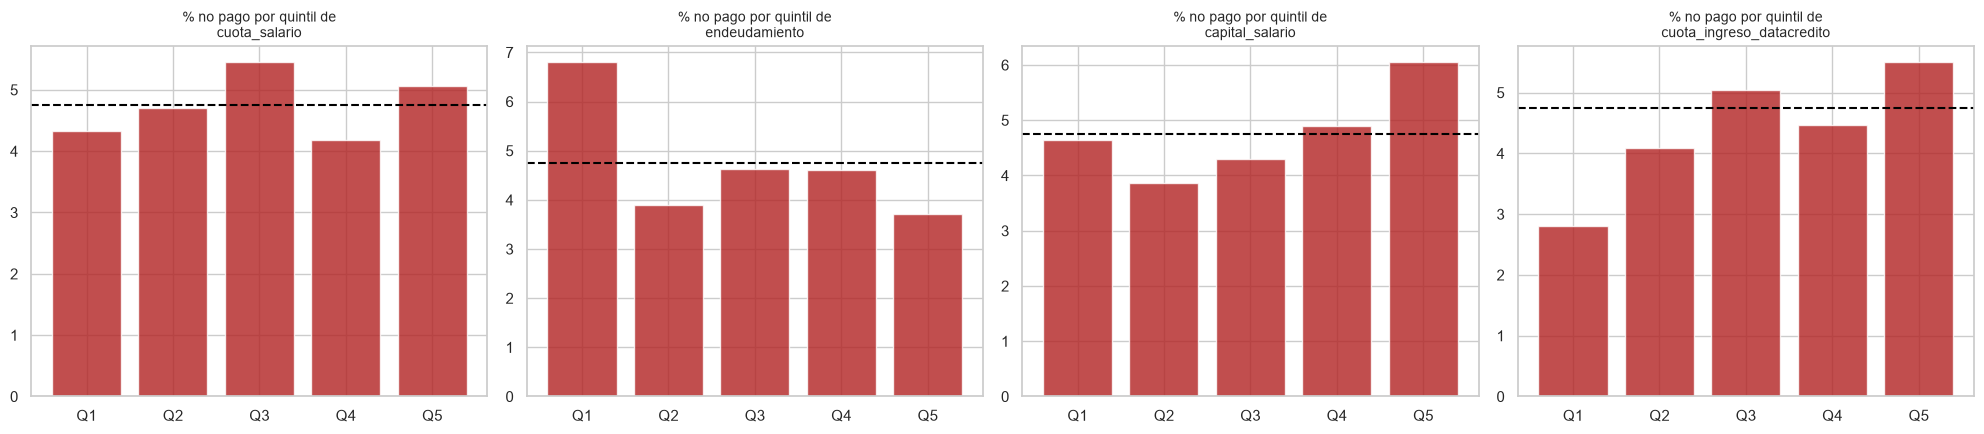

In [53]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col in zip(axes, nuevas_ratios):
    grupos = pd.qcut(df_deriv[col], 5, duplicates="drop")
    tabla = tasa_no_pago(df_deriv.assign(grupo=grupos).dropna(subset=["grupo"]), "grupo")
    ax.bar(range(len(tabla)), tabla["tasa_no_pago_pct"], color="firebrick", alpha=0.8)
    ax.set_xticks(range(len(tabla)))
    ax.set_xticklabels([f"Q{i + 1}" for i in range(len(tabla))])
    ax.axhline(TASA_GENERAL, color="black", linestyle="--")
    ax.set_title(f"% no pago por quintil de\n{col}", fontsize=10)
plt.tight_layout()
plt.show()

**Interpretación de los atributos derivados:**

| Atributo | Cálculo | Hallazgo |
|---|---|---|
| `tiene_mora` | `saldo_mora` > 0 | **El más fuerte:** 36,4 % de no pago frente a 4,6 % |
| `fin_de_semana` | Desembolso el sábado o domingo | ~6,3 % de no pago frente a ~4,1 % entre semana |
| `sin_info_datacredito` | Sin ingresos reportados al buró | 5,7 % de no pago frente a 4,4 % |
| `sin_historial_datacredito` | `puntaje_datacredito` = 0 | 6,9 % de no pago frente a 4,7 % (solo 145 clientes) |
| `capital_salario` | Capital / salario | El quintil más alto (préstamos grandes frente al ingreso) tiene más riesgo |
| `endeudamiento` | Otros préstamos / salario | Relación no lineal: el quintil más bajo tiene más riesgo, posiblemente clientes sin experiencia crediticia |
| `cuota_ingreso_datacredito` | Cuota / ingreso reportado al buró | **Patrón claro:** el no pago sube del 2,8 % (Q1) al 5,5 % (Q5). A mayor peso de la cuota sobre el ingreso real, más riesgo |
| `cuota_salario` | Cuota / salario declarado | Sin patrón claro, posiblemente porque el salario declarado es menos confiable que el ingreso del buró |
| `mes_prestamo`, `dia_semana` | Atributos de fecha | Capturan la estacionalidad vista en la sección 8.3 |
| `total_creditos_sectores` | Suma de créditos por sector | Resume el endeudamiento por número de créditos |

Los ratios tienen valores extremos (por ejemplo, una cuota de 125 veces el salario), causados por salarios mal registrados, así que también se deben **winsorizar**. Estos atributos se construirán dentro del pipeline de `ft_engineering.py`, para que se apliquen igual en el entrenamiento y en producción.

## 13. Conclusiones del EDA

La base de datos cuenta con 10763 registros y 23 variables, todos sin duplicados. El gran problema es el desbalance de la variable objetivo, ya que el 95,25 por ciento de los clientes son cumplidos mientras el 4,75 por ciento incumplen. Hallamos varios fallos de calidad explorando, entre ellos 58 datos malos en tendencia ingresos, 150 edades incoherentes, 24 salarios en cero, 8 puntajes de Datacredito errados y valores extremos en deudas poco creíbles. Ninguna variable numérica sigue una distribución normal y las monetarias tienen asimetría positiva, por eso, se recomienda aplicar log1p o winsorizacion. Debemos eliminar puntaje por fuga de información y tambien saldo mora codeudor al ser casi constante. Hay una redundancia alta entre saldo total y saldo principal con correlación de 0,95, al igual que pasa en otros pares de variables. Las señales de riesgo principales incluyen tener mora en los saldos, un puntaje Datacrédito bajo, bastantes consultas recientes al buró, ser joven o trabajador independiente. También influyen presentar ingresos que disminuyen, pedir montos altos, plazos largos, el tipo de crédito 6 y realizar desembolsos los fines de semana. Las relaciones entre las variables y el objetivo resultan débiles, siendo que algunas como el plazo o el endeudamiento no muestran linealidad. Se recomienda entonces evaluar modelos basados en árboles como Random Forest y XGBoost, comparándolos con la regresión logística para ver cuál predice mejor el incumplimiento de pago.